# Second Practice
### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336
##### We have been able to cooperate during almost all of the practice. Just individual reviewing and tweaking individually.

###### AI use has been marked in the code cells

In [1]:
# Necessary libraries
import numpy as np
import matplotlib.pyplot as plt

## 1. Gradient descent methods

### 1.1 A simple quadratic function

We will define $f$ as:
$$
    f(x)=x_{1}^{2} + x_{2}^{2}
$$

By differentiating, we obtain the gradient:
$$
    \nabla f(x) = (2x_{1}, 2x_{2})
$$

#### 1.1.1 Implement gradient descent with a constant $\alpha^{k} = 0.1$

In [2]:
def grad_desc(f, grad_f, x0, alpha, max_iter):
    x = x0
    for i in range(max_iter):
        x = x - alpha * grad_f(x)
    return x, f(x)

def f(x): return x[0]**2 + x[1]**2
def grad_f(x): return np.array([2*x[0], 2*x[1]])

In [3]:
x0 = np.random.uniform(-200, 200, 2)

x_final, f_final = grad_desc(f, grad_f, x0, alpha=0.1, max_iter=100)

print(f"Initial point: x0   = [{x0[0]:.4f}, {x0[1]:.4f}]")
print(f"Final point:   x    = [{x_final[0]:.2e}, {x_final[1]:.2e}]")
print(f"Final value:   f(x) = {f_final:.2e}")


Initial point: x0   = [-127.3523, 122.2852]
Final point:   x    = [-2.59e-08, 2.49e-08]
Final value:   f(x) = 1.29e-15


We see that the gradient descent converges to the point $(0, 0)$ where $f$ has a minimum. This point is indeed the minimum, as it is the only solution of $\nabla f(x) = 0$: $(2x_{1}, 2x_{2}) = (0, 0)$ only holds at $x = (0, 0)$.

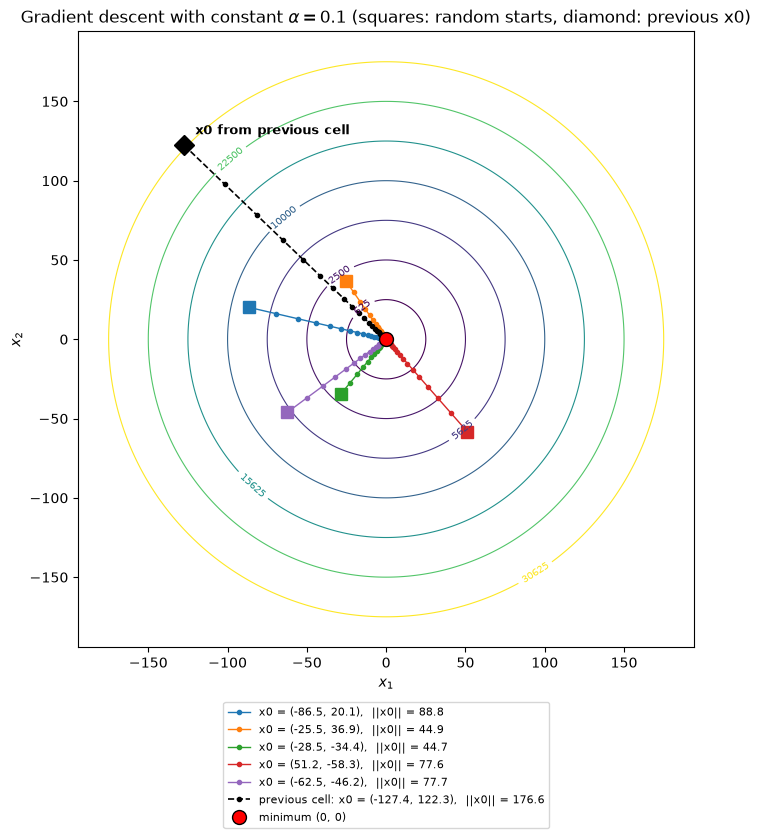

In [4]:
# PLOTS MADE WITH THE HELP OF AI

def grad_desc_path(grad_f, x0, alpha, max_iter):
    x = x0
    path = [x]
    for i in range(max_iter):
        x = x - alpha * grad_f(x)
        path.append(x)
    return np.array(path)

r = np.random.uniform(30, 100, 5)
theta = np.random.uniform(0, 2*np.pi, 5)
starts = np.column_stack([r*np.cos(theta), r*np.sin(theta)])

lim = 1.1 * max(100, np.linalg.norm(x0))
step = 10 if lim <= 120 else 25

X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
Z = f(np.array([X, Y]))

fig, ax = plt.subplots(figsize=(8, 8))
cs = ax.contour(X, Y, Z, levels=[k**2 for k in np.arange(step, lim, step)], cmap="viridis", linewidths=0.8)
ax.clabel(cs, fontsize=7, fmt="%.0f")

colors = plt.cm.tab10.colors
for i, start in enumerate(starts):
    path = grad_desc_path(grad_f, start, alpha=0.1, max_iter=100)
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
            label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
    ax.plot(*start, "s", color=colors[i], ms=9)

# x0 from the previous cell, drawn in black with a dashed line and a diamond
path = grad_desc_path(grad_f, x0, alpha=0.1, max_iter=100)
ax.plot(path[:, 0], path[:, 1], "--o", color="k", ms=3, lw=1.2,
        label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
ax.plot(*x0, "D", color="k", ms=10)
ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

ax.plot(0, 0, "o", color="red", mec="k", ms=10, label="minimum (0, 0)")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(r"Gradient descent with constant $\alpha = 0.1$ (squares: random starts, diamond: previous x0)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.show()

#### 1.1.2 Try again with $\alpha^{k} = 1$ and $\alpha^{k} = 2$

In [5]:
print(f"Initial point: x0   = [{x0[0]:.4f}, {x0[1]:.4f}]")

x_final_1, f_final_1 = grad_desc(f, grad_f, x0, alpha=1, max_iter=100)

print("\n\nalpha = 1")
print(f"Final point:   x    = [{x_final_1[0]:.4f}, {x_final_1[1]:.4f}]")
print(f"Final value:   f(x) = {f_final_1:.4f}")

x_final_2, f_final_2 = grad_desc(f, grad_f, x0, alpha=2, max_iter=100)

print("\n\nalpha = 2")
print(f"Final point:   x    = [{x_final_2[0]:.2e}, {x_final_2[1]:.2e}]")
print(f"Final value:   f(x) = {f_final_2:.2e}")

Initial point: x0   = [-127.3523, 122.2852]


alpha = 1
Final point:   x    = [-127.3523, 122.2852]
Final value:   f(x) = 31172.2750


alpha = 2
Final point:   x    = [-6.56e+49, 6.30e+49]
Final value:   f(x) = 8.28e+99


In [6]:
# MADE WITH THE HELP OF AI

path_1 = grad_desc_path(grad_f, x0, alpha=1, max_iter=100)
path_2 = grad_desc_path(grad_f, x0, alpha=2, max_iter=100)
dist_1 = np.linalg.norm(path_1, axis=1)
dist_2 = np.linalg.norm(path_2, axis=1)

print(f"{'k':>3} | {'x_k (alpha = 1)':>22} | {'||x_k|| (alpha = 1)':>20} | {'x_k (alpha = 2)':>26} | {'||x_k|| (alpha = 2)':>20}")
print("-" * 103)
for k, (p1, d1, p2, d2) in enumerate(zip(path_1, dist_1, path_2, dist_2)):
    point_1 = f"({p1[0]:.4f}, {p1[1]:.4f})"
    point_2 = f"({p2[0]:.4e}, {p2[1]:.4e})"
    print(f"{k:>3} | {point_1:>22} | {d1:>20.4f} | {point_2:>26} | {d2:>20.4e}")

  k |        x_k (alpha = 1) |  ||x_k|| (alpha = 1) |            x_k (alpha = 2) |  ||x_k|| (alpha = 2)
-------------------------------------------------------------------------------------------------------
  0 |  (-127.3523, 122.2852) |             176.5567 |  (-1.2735e+02, 1.2229e+02) |           1.7656e+02
  1 |  (127.3523, -122.2852) |             176.5567 |  (3.8206e+02, -3.6686e+02) |           5.2967e+02
  2 |  (-127.3523, 122.2852) |             176.5567 |  (-1.1462e+03, 1.1006e+03) |           1.5890e+03
  3 |  (127.3523, -122.2852) |             176.5567 |  (3.4385e+03, -3.3017e+03) |           4.7670e+03
  4 |  (-127.3523, 122.2852) |             176.5567 |  (-1.0316e+04, 9.9051e+03) |           1.4301e+04
  5 |  (127.3523, -122.2852) |             176.5567 |  (3.0947e+04, -2.9715e+04) |           4.2903e+04
  6 |  (-127.3523, 122.2852) |             176.5567 |  (-9.2840e+04, 8.9146e+04) |           1.2871e+05
  7 |  (127.3523, -122.2852) |             176.5567 |  (2.7852e+

Since $\nabla f(x) = 2x$, one step of gradient descent with constant $\alpha$ is
$$
    x^{k+1} = x^{k} - 2\alpha x^{k} = (1 - 2\alpha)\, x^{k}
    \quad\Longrightarrow\quad
    x^{k} = (1 - 2\alpha)^{k} x^{0}, \qquad \|x^{k}\| = |1 - 2\alpha|^{k}\, \|x^{0}\|
$$

- **$\alpha = 1$:** the factor is $1 - 2 = -1$, so $x^{k+1} = -x^{k}$. The iterates just bounce between $x^{0}$ and $-x^{0}$, and the distance to the minimum stays equal to $\|x^{0}\|$ in every iteration. The method never gets closer to $(0, 0)$.
- **$\alpha = 2$:** the factor is $1 - 4 = -3$, so the iterate changes sign and its distance to the minimum is multiplied by 3 in every iteration, the method diverges.

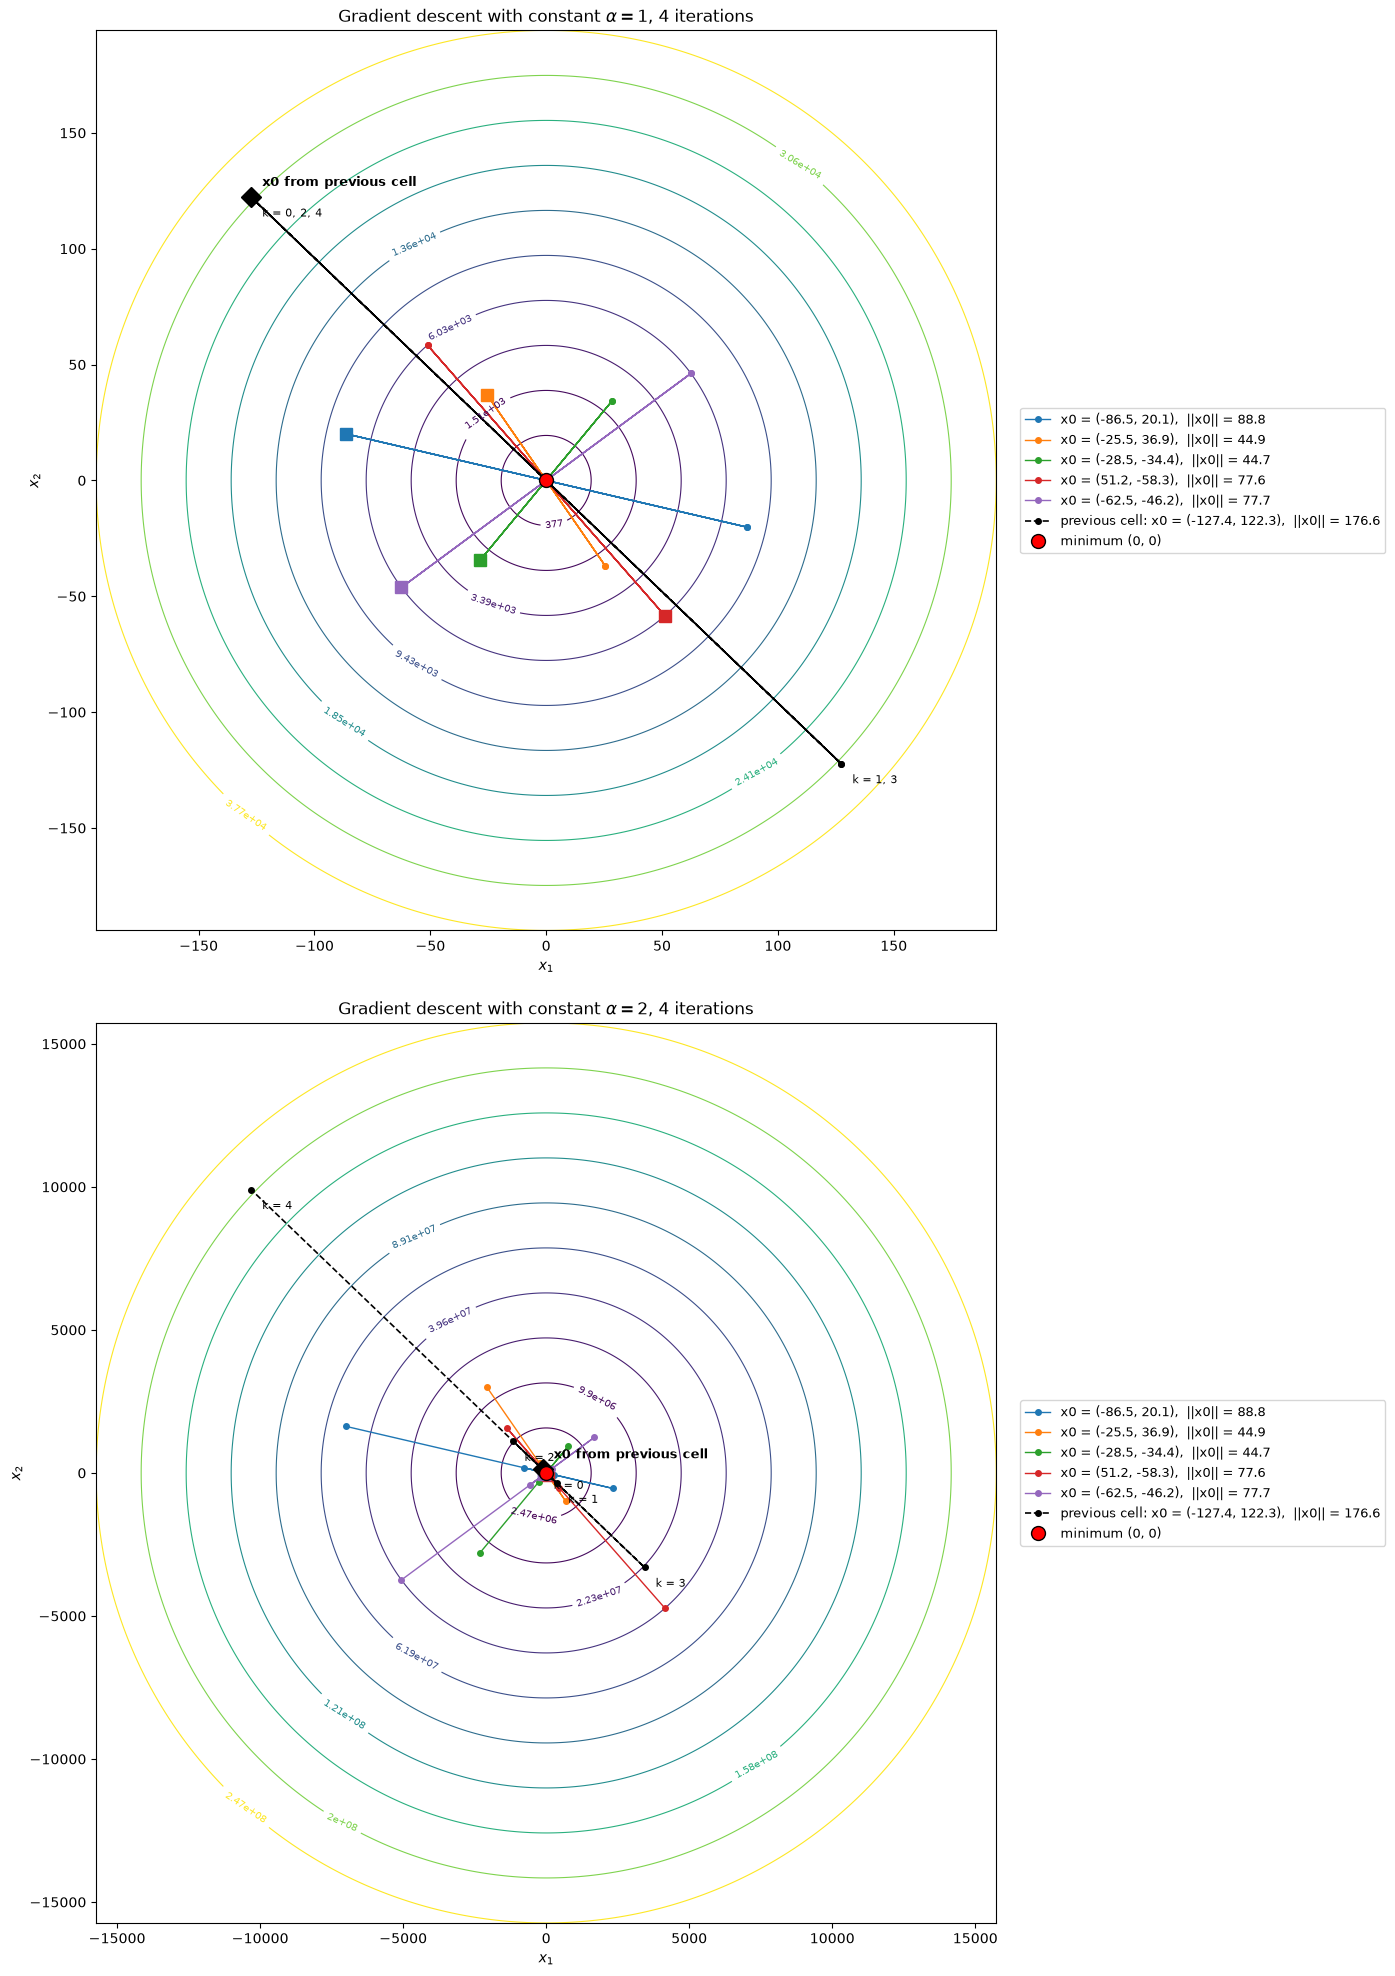

In [7]:
# PLOT MADE WITH THE HELP OF AI

fig, axes = plt.subplots(2, 1, figsize=(12, 20))
colors = plt.cm.tab10.colors

for ax, alpha in zip(axes, [1, 2]):
    paths = [grad_desc_path(grad_f, start, alpha=alpha, max_iter=4) for start in starts]
    path_prev = grad_desc_path(grad_f, x0, alpha=alpha, max_iter=4)

    lim = 1.1 * max(np.linalg.norm(p, axis=1).max() for p in paths + [path_prev])
    X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
    Z = f(np.array([X, Y]))
    cs = ax.contour(X, Y, Z, levels=np.linspace(0, lim, 11)[1:]**2, cmap="viridis", linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.3g")

    for i, (start, path) in enumerate(zip(starts, paths)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=4, lw=1,
                label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
        ax.plot(*start, "s", color=colors[i], ms=9)

    ax.plot(path_prev[:, 0], path_prev[:, 1], "--o", color="k", ms=4, lw=1.2,
            label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
    ax.plot(*x0, "D", color="k", ms=10)
    ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

    labels = {}
    for k, p in enumerate(path_prev):
        labels.setdefault(tuple(np.round(p, 6)), []).append(str(k))
    for p, ks in labels.items():
        ax.annotate("k = " + ", ".join(ks), p, xytext=(8, -14), textcoords="offset points", fontsize=8)

    ax.plot(0, 0, "o", color="red", mec="k", ms=10, label="minimum (0, 0)")
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(rf"Gradient descent with constant $\alpha = {alpha}$, 4 iterations")
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()

### 1.2 A function with multiple minima

We will now define $f$ as:
$$
    f(x) = x_{1}^{2}\left(4 - 2.1x_{1}^{2} + \tfrac{1}{3}x_{1}^{4}\right) + x_{1}x_{2} + x_{2}^{2}\left(-4 + 4x_{2}^{2}\right)
$$

By differentiating, we obtain the gradient:
$$
    \nabla f(x) = \left(8x_{1} - 8.4x_{1}^{3} + 2x_{1}^{5} + x_{2},\; x_{1} - 8x_{2} + 16x_{2}^{3}\right)
$$

and the Hessian:
$$
    \nabla^{2} f(x) = \begin{pmatrix} 8 - 25.2x_{1}^{2} + 10x_{1}^{4} & 1 \\ 1 & -8 + 48x_{2}^{2} \end{pmatrix}
$$


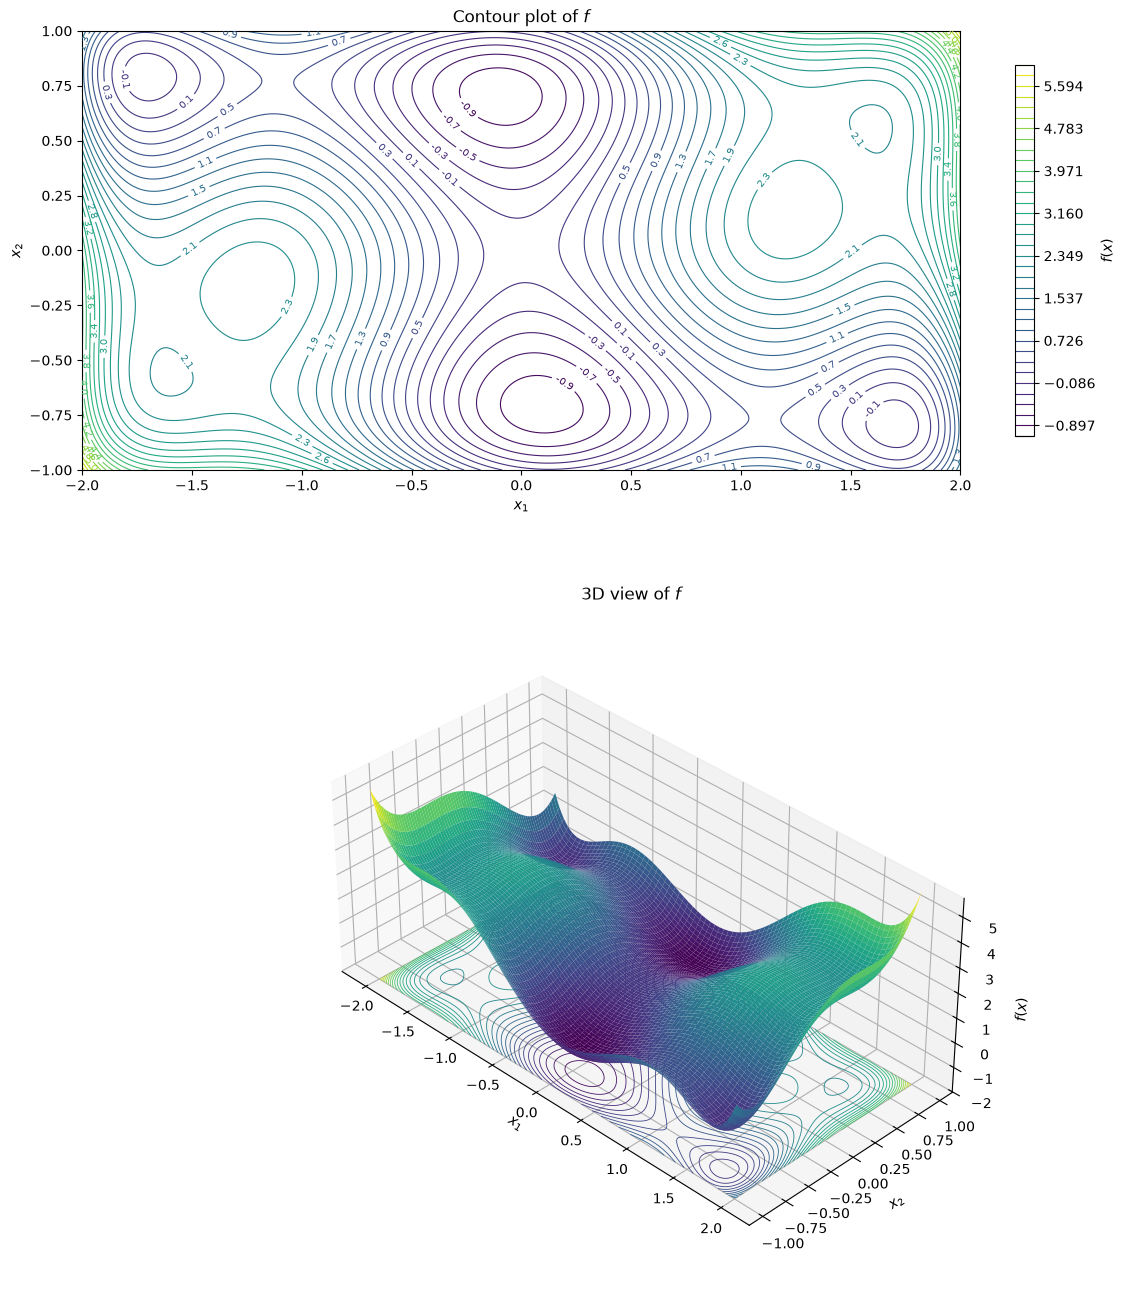

In [8]:
# PLOT MADE WITH THE HELP OF AI

def f_mm(x):
    return x[0]**2 * (4 - 2.1*x[0]**2 + x[0]**4/3) + x[0]*x[1] + x[1]**2 * (-4 + 4*x[1]**2)

def grad_f_mm(x):
    return np.array([8*x[0] - 8.4*x[0]**3 + 2*x[0]**5 + x[1],
                     x[0] - 8*x[1] + 16*x[1]**3])

minima = np.array([[-0.0898,  0.7127], [ 0.0898, -0.7127],
                   [ 1.7036, -0.7961], [-1.7036,  0.7961],
                   [ 1.6071,  0.5687], [-1.6071, -0.5687]])

X1, X2 = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 1, 400))
Z_mm = f_mm(np.array([X1, X2]))
levels_mm = np.linspace(-1.1, 6, 36)

def contour_mm(ax, show_minima=True):
    cs = ax.contour(X1, X2, Z_mm, levels=levels_mm, cmap="viridis", linewidths=0.8)
    if show_minima:
        ax.plot(minima[:2, 0], minima[:2, 1], "o", color="red", mec="k", ms=10, label="global minima")
        ax.plot(minima[2:, 0], minima[2:, 1], "o", mfc="none", mec="red", mew=2, ms=10, label="local minima")
    ax.set_xlim(-2, 2); ax.set_ylim(-1, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    return cs

fig = plt.figure(figsize=(12, 14))

ax = fig.add_subplot(2, 1, 1)
cs = contour_mm(ax, show_minima=False)
ax.clabel(cs, fontsize=7, fmt="%.1f")
fig.colorbar(cs, ax=ax, label="$f(x)$", shrink=0.55)
ax.set_title("Contour plot of $f$")

ax3d = fig.add_subplot(2, 1, 2, projection="3d")
ax3d.plot_surface(X1, X2, Z_mm, cmap="viridis", rstride=5, cstride=5, linewidth=0, antialiased=True)
ax3d.contour(X1, X2, Z_mm, levels=levels_mm, cmap="viridis", linewidths=0.6, offset=Z_mm.min() - 1)
ax3d.set_zlim(Z_mm.min() - 1, Z_mm.max())
ax3d.set_xlabel("$x_1$"); ax3d.set_ylabel("$x_2$"); ax3d.set_zlabel("$f(x)$")
ax3d.set_box_aspect((2, 1, 0.8))
ax3d.view_init(elev=35, azim=-45)
ax3d.set_title("3D view of $f$")

plt.tight_layout()
plt.show()

#### 1.2.1 Gradient descent with a constant $\alpha^{k} = 0.1$ from different starting points

                x0 |   x after 100 iterations |     f(x) | ||grad f(x)||
--------------------------------------------------------------------------
 (-1.5000, 0.8000) |        (-1.6221, 0.9095) |   0.0110 |    3.4065e+00
 (1.5000, -0.8000) |        (1.6221, -0.9095) |   0.0110 |    3.4065e+00
  (0.5000, 0.5000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
(-0.5000, -0.5000) |        (0.0898, -0.7127) |  -1.0316 |    1.7902e-15
  (1.0000, 0.9000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
(-1.9000, -0.9000) |        (0.0898, -0.7127) |  -1.0316 |    1.7902e-15
  (1.9000, 0.2000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
 (-1.0000, 0.0000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
  (1.4000, 0.3000) |         (1.6071, 0.5687) |   2.1043 |    1.8310e-15


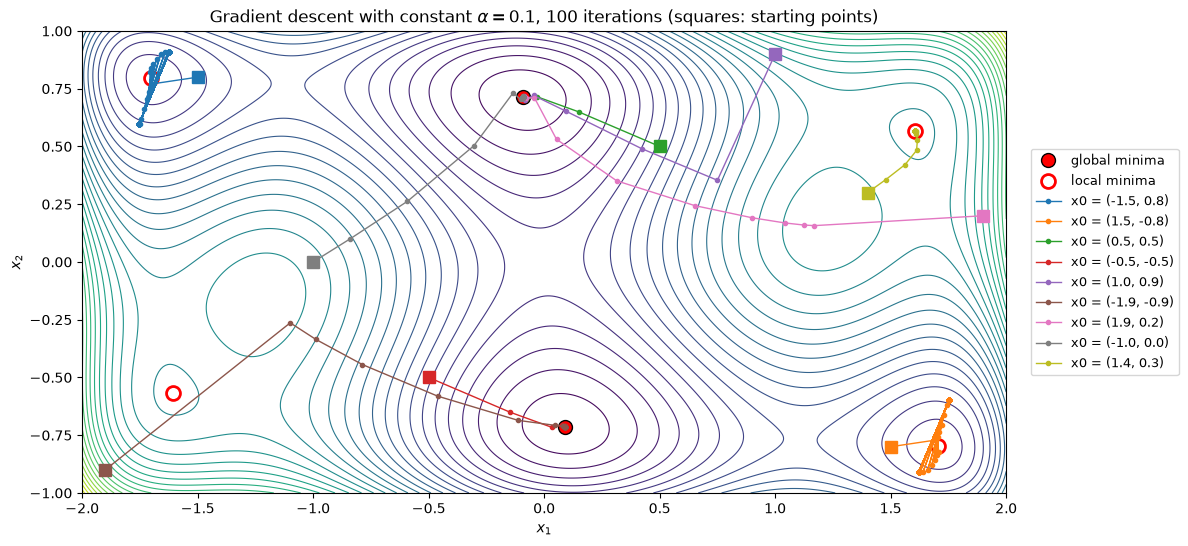

In [9]:
# MADE WITH THE HELP OF AI

starts_mm = np.array([[-1.5,  0.8], [ 1.5, -0.8], [ 0.5,  0.5], [-0.5, -0.5],
                      [ 1.0,  0.9], [-1.9, -0.9], [ 1.9,  0.2], [-1.0,  0.0],
                      [ 1.4,  0.3]])

paths_const = [grad_desc_path(grad_f_mm, x0_mm, alpha=0.1, max_iter=100) for x0_mm in starts_mm]

print(f"{'x0':>18} | {'x after 100 iterations':>24} | {'f(x)':>8} | {'||grad f(x)||':>13}")
print("-" * 74)
for x0_mm, path in zip(starts_mm, paths_const):
    x = path[-1]
    print(f"{f'({x0_mm[0]:.4f}, {x0_mm[1]:.4f})':>18} | {f'({x[0]:.4f}, {x[1]:.4f})':>24} | "
          f"{f_mm(x):>8.4f} | {np.linalg.norm(grad_f_mm(x)):>13.4e}")

fig, ax = plt.subplots(figsize=(12, 6))
contour_mm(ax)
colors = plt.cm.tab10.colors
for i, (x0_mm, path) in enumerate(zip(starts_mm, paths_const)):
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
            label=f"x0 = ({x0_mm[0]:.1f}, {x0_mm[1]:.1f})")
    ax.plot(*x0_mm, "s", color=colors[i], ms=9)
ax.set_title(r"Gradient descent with constant $\alpha = 0.1$, 100 iterations (squares: starting points)")
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

Conclusions

- Most starting points converge to the minimum of their valley. Only 2 of the 9 starting points don't converge after 100 iterations. Of the 7 that converge, 5 end up in their "valley's minimum"; the other 2 take a first step that is too big and move to another valley.

- From $(\pm 1.5, \mp 0.8)$ the method does not converge. The iterates end up jumping between two points around the local minima $(\pm 1.7036, \mp 0.7961)$, with $\|\nabla f\| \approx 3.4$ after 100 iterations. This is the same problem as with $\alpha = 1$ in 1.1.2. In other words, the valley of $(\pm 1.7036, \mp 0.7961)$ is too steep for $\alpha = 0.1$. Every step overshoots the minimum.

#### 1.2.2 Gradient descent with backtracking

At every iteration we start with $\alpha^{k} = 1$ and halve it until $f(x^{k} - \alpha^{k}\nabla f(x^{k})) < f(x^{k})$. Then we update $x^{k+1} = x^{k} - \alpha^{k}\nabla f(x^{k})$ and, in the next iteration, $\alpha$ starts again at 1. Instead of a fixed number of iterations, we stop when $\|\nabla f(x^{k})\| < 10^{-5}$ (with at most 100 iterations). To compare both methods fairly, we also run the constant step $\alpha = 0.1$ with the same stopping criterion, from the same starting points as in 1.2.1.

Stopping criterion: ||grad f(x)|| < 1e-5 (at most 100 iterations)

                x0 |         constant alpha = 0.1         |                  backtracking                 
                   | iterations |                 final x | iterations | halvings |                final x
----------------------------------------------------------------------------------------------------------
 (-1.5000, 0.8000) |       >100 |       (-1.6221, 0.9095) |         15 |       59 |      (-1.7036, 0.7961)
 (1.5000, -0.8000) |       >100 |       (1.6221, -0.9095) |         15 |       59 |      (1.7036, -0.7961)
  (0.5000, 0.5000) |         25 |       (-0.0898, 0.7127) |         10 |       33 |      (-0.0898, 0.7127)
(-0.5000, -0.5000) |         25 |       (0.0898, -0.7127) |         10 |       33 |      (0.0898, -0.7127)
  (1.0000, 0.9000) |         28 |       (-0.0898, 0.7127) |         10 |       34 |      (0.0898, -0.7127)
(-1.9000, -0.9000) |         19 |       (0.0898, -0.7127) |         11 |     

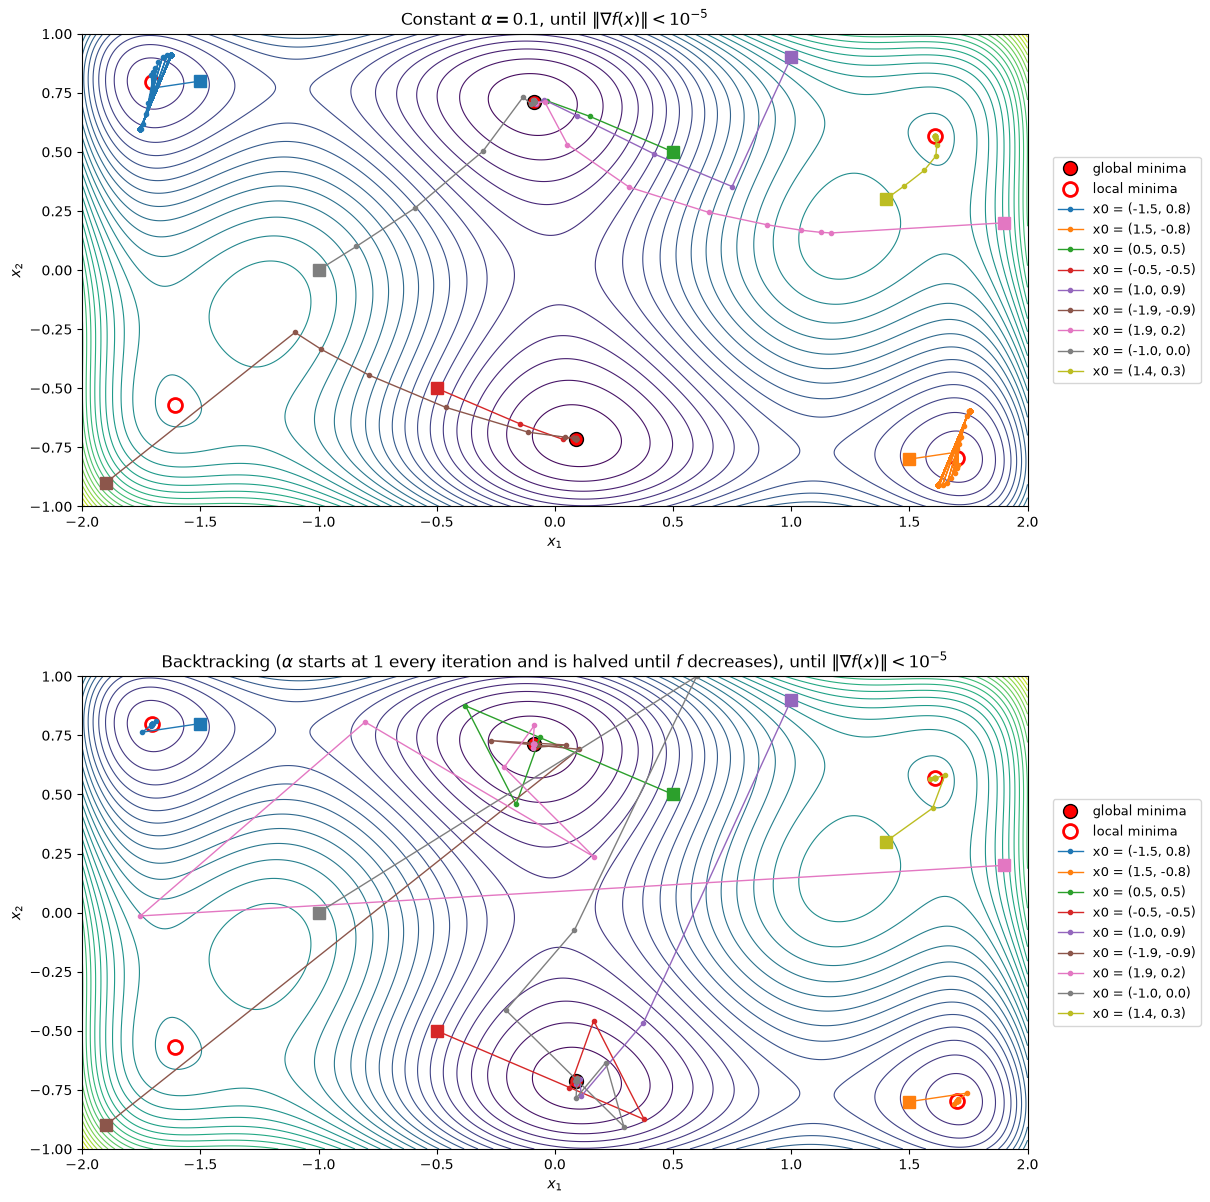

In [10]:
# PLOTTING MADE WITH THE HELP OF AI

def grad_desc_backtracking(f, grad_f, x0, alpha0=1, reset=True, tol=1e-5, max_iter=100, alpha_min=1e-5):
    x = x0
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        if reset:
            alpha = alpha0
        while f(x - alpha * grad) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

def grad_desc_tol(grad_f, x0, alpha=0.1, tol=1e-5, max_iter=100):
    x = x0
    path = [x]
    for k in range(max_iter):
        if np.linalg.norm(grad_f(x)) < tol:
            break
        x = x - alpha * grad_f(x)
        path.append(x)
    return np.array(path)

results_bt = [grad_desc_backtracking(f_mm, grad_f_mm, x0_mm) for x0_mm in starts_mm]
paths_tol = [grad_desc_tol(grad_f_mm, x0_mm, alpha=0.1) for x0_mm in starts_mm]

print("Stopping criterion: ||grad f(x)|| < 1e-5 (at most 100 iterations)\n")
print(f"{'x0':>18} | {'constant alpha = 0.1':^36} | {'backtracking':^46}")
print(f"{'':>18} | {'iterations':>10} | {'final x':>23} | {'iterations':>10} | {'halvings':>8} | {'final x':>22}")
print("-" * 106)
for x0_mm, p_tol, (p_bt, alphas, n_halv) in zip(starts_mm, paths_tol, results_bt):
    it_tol = len(p_tol) - 1
    it_tol = f"{it_tol}" if np.linalg.norm(grad_f_mm(p_tol[-1])) < 1e-5 else f">{it_tol}"
    print(f"{f'({x0_mm[0]:.4f}, {x0_mm[1]:.4f})':>18} | {it_tol:>10} | {f'({p_tol[-1][0]:.4f}, {p_tol[-1][1]:.4f})':>23} | "
          f"{len(p_bt) - 1:>10} | {n_halv:>8} | {f'({p_bt[-1][0]:.4f}, {p_bt[-1][1]:.4f})':>22}")

fig, axes = plt.subplots(2, 1, figsize=(12, 13))
for ax, paths, title in zip(axes, [paths_tol, [r[0] for r in results_bt]],
                            [r"Constant $\alpha = 0.1$", r"Backtracking ($\alpha$ starts at 1 every iteration and is halved until $f$ decreases)"]):
    contour_mm(ax)
    for i, (x0_mm, path) in enumerate(zip(starts_mm, paths)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
                label=f"x0 = ({x0_mm[0]:.1f}, {x0_mm[1]:.1f})")
        ax.plot(*x0_mm, "s", color=colors[i], ms=9)
    ax.set_title(title + r", until $\|\nabla f(x)\| < 10^{-5}$")
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

Conclusions

- All 9 starting points now converge, and in 10 to 15 iterations, while with $\alpha = 0.1$ they needed 13 to 29 (or did not converge in 100). Backtracking is faster because it takes the largest step (of the form $1/2^{j}$) that decreases $f$, instead of always taking the same small one.
- The points that didn't converge now do. From $(\pm 1.5, \mp 0.8)$ with $\alpha = 0.1$ the method got stuck jumping between two points; now $\alpha$ ends up being $0.0625$, small enough for that steep valley, and it reaches $(\pm 1.7036, \mp 0.7961)$ in 15 iterations.
- The price is the number of halvings: since $\alpha$ starts at 1 every iteration, it has to be halved again each time (28 to 59 halvings in total), so each iteration needs several evaluations of $f$.
- Starting with $\alpha = 1$ makes the first steps very long, so the problem of starting points missing their "valley's minimum" is even more visible. For example, $(-1.9, -0.9)$ jumps directly to the global minimum $(-0.0898, 0.7127)$ on the other side of the box, and $(1.0, 0.9)$ and $(-1.0, 0.0)$ end at a different global minimum than with $\alpha = 0.1$. Backtracking only asks $f$ to decrease, it does not care about which valley the new point is in.

### 1.3 The Rosenbrock function

We will now define $f$ as:
$$
    f(x) = (a - x_{1})^{2} + b\,(x_{2} - x_{1}^{2})^{2}, \qquad a = 1,\; b = 100
$$

By differentiating, we obtain the gradient:
$$
    \nabla f(x) = \left(-2(a - x_{1}) - 4b\,x_{1}(x_{2} - x_{1}^{2}),\; 2b\,(x_{2} - x_{1}^{2})\right)
$$

The only minimum is at $(x_{1}^{*}, x_{2}^{*}) = (a, a^{2}) = (1, 1)$, where $f = 0$, since both terms of $f$ are squares and vanish there. It lies at the bottom of a long, narrow and curved valley.

#### 1.3.1 Contour plot of the Rosenbrock function with the gradient

In [11]:
a, b = 1, 100

def f_rosen(x): return (a - x[0])**2 + b * (x[1] - x[0]**2)**2
def grad_f_rosen(x):
    return np.array([-2*(a - x[0]) - 4*b*x[0]*(x[1] - x[0]**2),
                     2*b*(x[1] - x[0]**2)])

x = np.array([-1.2, 1.0]); h = 1e-6
num = np.array([(f_rosen(x + h*e) - f_rosen(x - h*e)) / (2*h) for e in np.eye(2)])
print("analytical gradient:", grad_f_rosen(x))
print("numerical gradient: ", num)

analytical gradient: [-215.6  -88. ]
numerical gradient:  [-215.59999998  -88.        ]


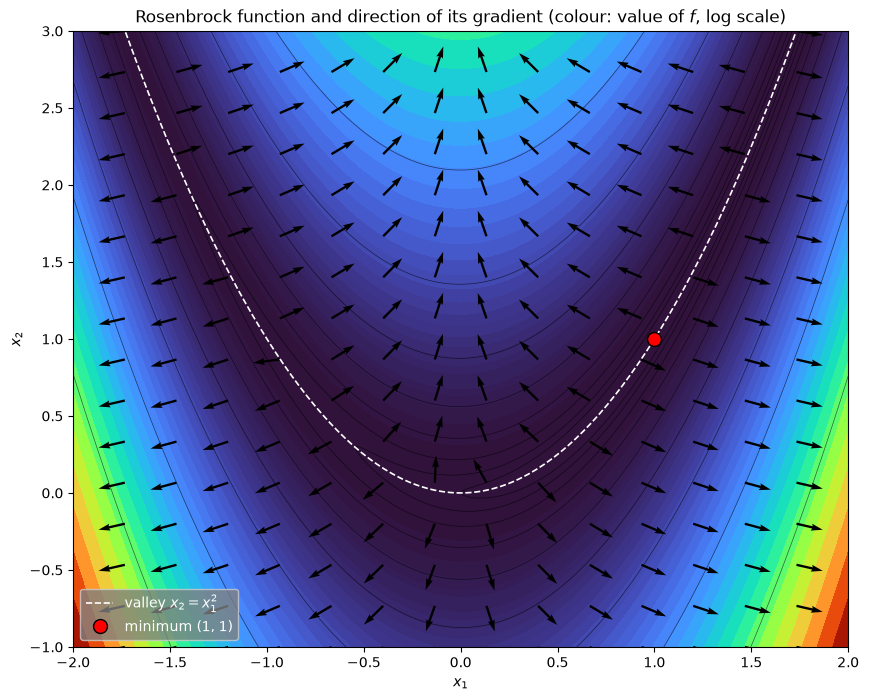

In [12]:
# PLOT MADE WITH THE HELP OF AI

X1r, X2r = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
Z_r = f_rosen(np.array([X1r, X2r]))

fig, ax = plt.subplots(figsize=(10, 8))
ax.contourf(X1r, X2r, Z_r, levels=np.geomspace(1, Z_r.max(), 60), cmap="turbo", extend="min")
ax.contour(X1r, X2r, Z_r, levels=np.geomspace(1, Z_r.max(), 10), colors="k", linewidths=0.5, alpha=0.6)

xg, yg = np.meshgrid(np.linspace(-2, 2, 16), np.linspace(-1, 3, 16))
G = grad_f_rosen(np.array([xg, yg]))
norm = np.hypot(G[0], G[1])
ax.quiver(xg, yg, G[0]/norm, G[1]/norm, color="k", angles="xy", width=0.003)

xs = np.linspace(-2, 2, 200)
ax.plot(xs, xs**2, "w--", lw=1.2, label="valley $x_2 = x_1^2$")
ax.plot(1, 1, "o", color="red", mec="k", ms=10, label="minimum (1, 1)")
ax.set_xlim(-2, 2); ax.set_ylim(-1, 3)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Rosenbrock function and direction of its gradient (colour: value of $f$, log scale)")
ax.legend(loc="lower left", facecolor="gray", labelcolor="white")
plt.show()

#### 1.3.2 Gradient descent with backtracking from different starting points

We use the backtracking algorithm of 1.2.2, but starting with $\alpha = 0.1$ instead of $\alpha = 1$, as 1 was too extreme as a first step: the gradient of the Rosenbrock function is very large away from the valley (e.g. $\|\nabla f(-1.2, 1)\| \approx 233$), so a step with $\alpha = 1$ lands extremely far away and $\alpha$ has to be halved about 9 times in every iteration. For the same reason $\alpha$ is not reset between iterations: the one accepted in iteration $k$ is the starting value for iteration $k+1$, so $\alpha$ can only decrease. This time we do not limit the iterations to 100, we stop when $\|\nabla f(x^{k})\| < 10^{-5}$. We try six starting points and check how close the last point is to the minimum $(1, 1)$.

After that, we also look at what would have happened with the other criterion of the statement, $|f(x^{k+1}) - f(x^{k})| < 10^{-3}$, using the same runs.

In [13]:
starts_r = np.array([[-1.2, 1.0], [-1.5, 2.0], [0.0, 0.0], [2.0, 2.0], [-1.0, -0.5], [0.0, 2.0]])

# max_iter = 1000000, just in case
results_r = [grad_desc_backtracking(f_rosen, grad_f_rosen, x0, alpha0=0.1, reset=False, tol=1e-5, max_iter=1000000) for x0 in starts_r]

print("Stopping criterion: ||grad f(x)|| < 1e-5\n")
print(f"{'x0':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 89)
for x0, (path, alphas, n_halv) in zip(starts_r, results_r):
    x = path[-1]
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(path) - 1:>10} | {n_halv:>8} | {f'({x[0]:.4f}, {x[1]:.4f})':>20} | "
          f"{f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e}")

print("\nStopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-3 (first iteration where it holds)\n")
print(f"{'x0':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 89)
for x0, (path, alphas, n_halv) in zip(starts_r, results_r):
    f_path = np.array([f_rosen(p) for p in path])
    k = np.argmax(np.abs(np.diff(f_path)) < 1e-3) + 1
    x = path[k]
    halv_k = int(round(np.log2(0.1 / alphas[k - 1])))
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {k:>10} | {halv_k:>8} | {f'({x[0]:.4f}, {x[1]:.4f})':>20} | "
          f"{f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e}")

Stopping criterion: ||grad f(x)|| < 1e-5

                x0 | iterations | halvings |              final x |      f(x) | ||grad f(x)||
-----------------------------------------------------------------------------------------
 (-1.2000, 1.0000) |      36586 |        7 |     (1.0000, 1.0000) |  1.25e-10 |      1.00e-05
 (-1.5000, 2.0000) |      34470 |        7 |     (1.0000, 1.0000) |  1.25e-10 |      1.00e-05
  (0.0000, 0.0000) |      15616 |        6 |     (1.0000, 1.0000) |  1.25e-10 |      1.00e-05
  (2.0000, 2.0000) |      35731 |        7 |     (1.0000, 1.0000) |  1.25e-10 |      1.00e-05
(-1.0000, -0.5000) |      15544 |        6 |     (1.0000, 1.0000) |  1.25e-10 |      1.00e-05
  (0.0000, 2.0000) |      15607 |        6 |     (1.0000, 1.0000) |  1.25e-10 |      1.00e-05

Stopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-3 (first iteration where it holds)

                x0 | iterations | halvings |              final x |      f(x) | ||grad f(x)||
--------------------------------

With the first criterion, we see that all 6 points end up reaching the minimum but take a long time to reach it, with very little halving, 6 or 7 in total, as $\alpha$ is only halved at the beginning and then it stays constant.

On the other hand, we see that with the second criterion, as convergence is difficult in this function, all the sequences halted before getting close to the minimum: the gradient is bigger than 0.3 and the points are far from $(1, 1)$. It is also interesting to see how much faster they reached the stopping criterion compared to the first one and, consequently, with the same number of halvings or fewer (4 to 7).

Now we try again with a stopping criterion of $\left| f(x_{k+1}) - f(x_{k}) \right| < 10^{-8}$

In [14]:
print("\nStopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-8 (first iteration where it holds)\n")
print(f"{'x0':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 89)
for x0, (path, alphas, n_halv) in zip(starts_r, results_r):
    f_path = np.array([f_rosen(p) for p in path])
    k = np.argmax(np.abs(np.diff(f_path)) < 1e-8) + 1
    x = path[k]
    halv_k = int(round(np.log2(0.1 / alphas[k - 1])))
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {k:>10} | {halv_k:>8} | {f'({x[0]:.4f}, {x[1]:.4f})':>20} | "
          f"{f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e}")


Stopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-8 (first iteration where it holds)

                x0 | iterations | halvings |              final x |      f(x) | ||grad f(x)||
-----------------------------------------------------------------------------------------
 (-1.2000, 1.0000) |      17714 |        7 |     (1.0040, 1.0081) |  1.61e-05 |      3.58e-03
 (-1.5000, 2.0000) |      15658 |        7 |     (0.9960, 0.9920) |  1.59e-05 |      3.58e-03
  (0.0000, 0.0000) |       6763 |        6 |     (0.9972, 0.9944) |  7.96e-06 |      2.53e-03
  (2.0000, 2.0000) |      16858 |        7 |     (1.0040, 1.0081) |  1.61e-05 |      3.58e-03
(-1.0000, -0.5000) |       6691 |        6 |     (0.9972, 0.9944) |  7.96e-06 |      2.53e-03
  (0.0000, 2.0000) |       6754 |        6 |     (0.9972, 0.9944) |  7.96e-06 |      2.53e-03


With this much stricter stopping criterion, the sequence stopped much closer to $(1, 1)$. However, it is still not as close as with the criterion on the gradient, which makes sense, as this criterion is easier to reach when the slope is almost flat.

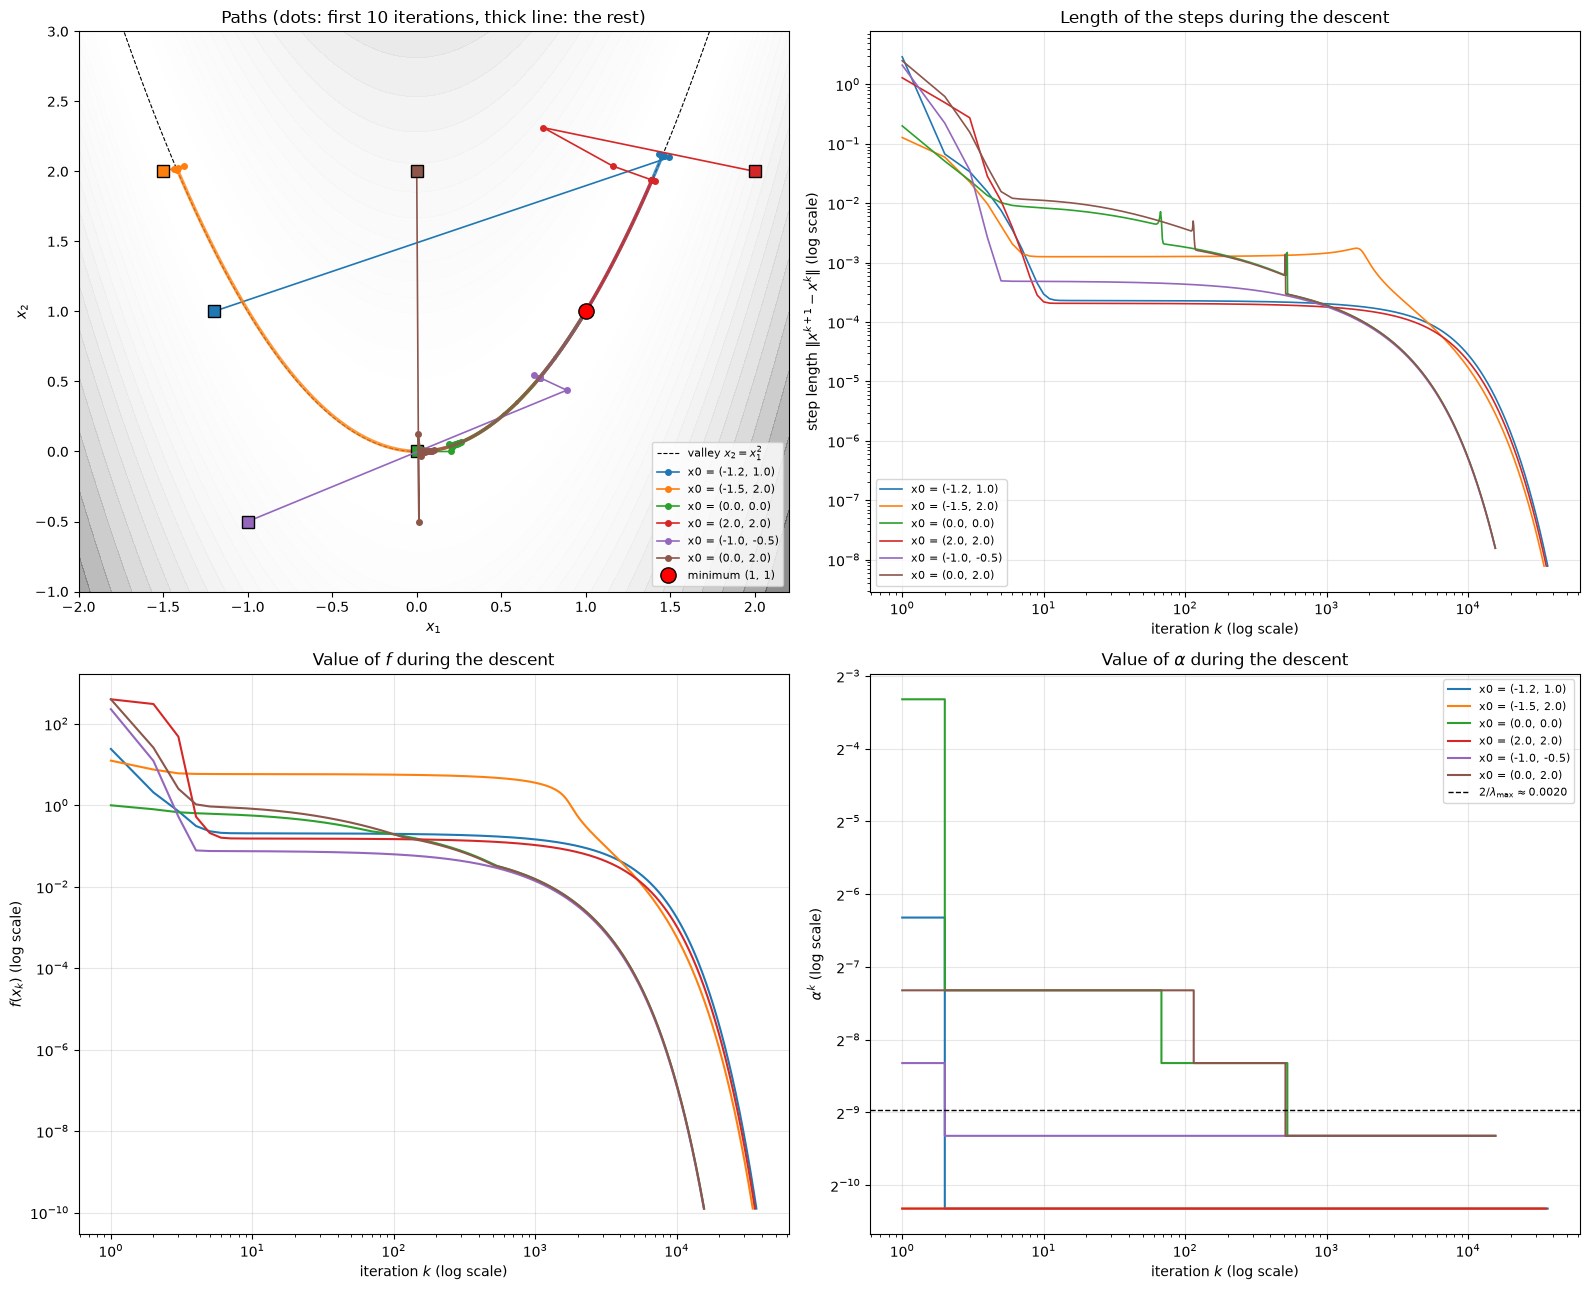

In [15]:
# INTERESTING PLOTS CLAUDE PROPOSED TO MAKE THAT WE FOUND TO GIVE USEFUL INSIGHTS

colors = plt.cm.tab10.colors
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.ravel()

# 1)
X1p, X2p = np.meshgrid(np.linspace(-2, 2.2, 400), np.linspace(-1, 3, 400))
Z_p = f_rosen(np.array([X1p, X2p]))
axes[0].contourf(X1p, X2p, Z_p, levels=np.geomspace(1, Z_p.max(), 40), cmap="Greys", alpha=0.5, extend="min")
xs = np.linspace(-2, 2.2, 200)
axes[0].plot(xs, xs**2, "k--", lw=0.8, label="valley $x_2 = x_1^2$")
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    axes[0].plot(path[:11, 0], path[:11, 1], "-o", color=colors[i], lw=1.2, ms=4,
                 label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
    axes[0].plot(path[10:, 0], path[10:, 1], "-", color=colors[i], lw=2.5, alpha=0.8)
    axes[0].plot(*x0, "s", color=colors[i], mec="k", ms=9)
axes[0].plot(1, 1, "o", color="red", mec="k", ms=11, label="minimum (1, 1)")
axes[0].set_xlim(-2, 2.2); axes[0].set_ylim(-1, 3)
axes[0].set_xlabel("$x_1$"); axes[0].set_ylabel("$x_2$")
axes[0].set_title("Paths (dots: first 10 iterations, thick line: the rest)")
axes[0].legend(fontsize=8, loc="lower right")

# 2)
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    step_len = np.linalg.norm(np.diff(path, axis=0), axis=1)
    axes[1].loglog(np.arange(1, len(step_len) + 1), step_len, color=colors[i], lw=1.2,
                   label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
axes[1].set_xlabel("iteration $k$ (log scale)")
axes[1].set_ylabel(r"step length $\|x^{k+1} - x^{k}\|$ (log scale)")
axes[1].set_title("Length of the steps during the descent")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="lower left")

# 3)
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    axes[2].loglog(np.arange(1, len(path) + 1), [f_rosen(p) for p in path], color=colors[i])
axes[2].set_xlabel("iteration $k$ (log scale)"); axes[2].set_ylabel("$f(x_k)$ (log scale)")
axes[2].set_title("Value of $f$ during the descent")
axes[2].grid(alpha=0.3)

# 4)
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    axes[3].step(np.arange(1, len(alphas) + 1), alphas, where="post", color=colors[i], lw=1.5,
                 label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
lam_max = np.linalg.eigvalsh(np.array([[802, -400], [-400, 200]])).max()
axes[3].axhline(2 / lam_max, color="k", ls="--", lw=1, label=r"$2/\lambda_{\max} \approx 0.0020$")
axes[3].set_xscale("log"); axes[3].set_yscale("log", base=2)
axes[3].set_xlabel("iteration $k$ (log scale)"); axes[3].set_ylabel(r"$\alpha^{k}$ (log scale)")
axes[3].set_title(r"Value of $\alpha$ during the descent")
axes[3].grid(alpha=0.3)
axes[3].legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

Conclusions

- It reaches the minimum, but it needs a huge number of iterations. From the six starting points the algorithm stops after thousands of iterations, far more than the 10 to 15 needed for the multiple-minima function in 1.2.2. All the runs end at or very close to $(1, 1)$.
- After a few iterations, the sequence is inside the valley, and from there $f$ decreases very slowly, as the plot of $f(x^{k})$ shows: it goes down in steps at the beginning and then almost in a straight line (in log scale).
- Inside the valley the steps are tiny. The plot of the step length shows that, after the first 10 iterations, the steps are only between $10^{-2}$ and $10^{-4}$ long, and they stay like that for thousands of iterations before decreasing, so the iterate follows the valley very slowly towards $(1, 1)$. There is no zig-zag from one side of the valley to the other at this point. The oscillation across the valley dies out after a few iterations, and what is left is a slow and steady advance along the valley floor.
- The number of iterations is high because, outside the valley, the gradient of $f$ is very large and almost perpendicular to the valley, so $\alpha$ becomes small very quickly. Once the iterates reach the valley, where the gradient is small, this small $\alpha$ makes every step tiny, and a large number of steps is needed to reach the minimum.
- The dashed line in the plot of $\alpha$ shows how small it has to be. Near the minimum the Hessian is
$$
    \nabla^{2} f(1, 1) = \begin{pmatrix} 802 & -400 \\ -400 & 200 \end{pmatrix}, \qquad \lambda_{\min} \approx 0.4, \quad \lambda_{\max} \approx 1001.6
$$
  and, with the same argument as in 1.1.2 applied to each eigenvector, the gradient descent only converges if $\alpha < 2/\lambda_{\max} \approx 0.0020$. The accepted $\alpha$ ends just below that line ($0.1/2^{6} \approx 0.0016$ or $0.1/2^{7} \approx 0.00078$), but then the error along the valley (the direction of $\lambda_{\min}$) is only multiplied by $1 - \alpha\lambda_{\min} \approx 0.999$ at every iteration, which is why so many iterations are needed. The ratio $\lambda_{\max}/\lambda_{\min} \approx 2500$ shows that the function is badly scaled.

## 2. Newton descent method

### 2.1 A simple quadratic function

We will now define $f$ as:
$$
    f(x) = 100x_{1}^{2} + x_{2}^{2}
$$

By differentiating, we obtain the gradient:
$$
    \nabla f(x) = (200x_{1},\; 2x_{2})
$$

and the Hessian:
$$
    \nabla^{2} f(x) = \begin{pmatrix} 200 & 0 \\ 0 & 2 \end{pmatrix}
$$

The Hessian is constant and positive definite (eigenvalues 200 and 2), so $f$ is convex and its only minimum is $(0, 0)$. Its contour lines are ellipses 10 times longer in the $x_2$ direction than in the $x_1$ direction.

#### 2.1.1 Gradient descent with backtracking

We use the backtracking algorithm of 1.2.2: $\alpha$ starts at 1 every iteration and is halved until $f$ decreases. We stop when $\|\nabla f(x^{k})\| < 10^{-5}$, and we count how many iterations are needed from six starting points.

In [16]:
def f_q(x): return 100*x[0]**2 + x[1]**2
def grad_f_q(x): return np.array([200*x[0], 2*x[1]])
def hess_f_q(x): return np.array([[200, 0], [0, 2]])

starts_q = np.array([[1.0, 1.0], [-2.0, 1.5], [0.5, -2.0], [-1.5, -1.0], [2.0, 0.1], [0.1, 2.0]])

results_gd_q = [grad_desc_backtracking(f_q, grad_f_q, x0, tol=1e-5, max_iter=100000) for x0 in starts_q]

print("Gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5\n")
print(f"{'x0':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>22} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 95)
for x0, (path, alphas, n_halv) in zip(starts_q, results_gd_q):
    x = path[-1]
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(path) - 1:>10} | {n_halv:>8} | {f'({x[0]:.4f}, {x[1]:.4f})':>22} | "
          f"{f_q(x):>9.2e} | {np.linalg.norm(grad_f_q(x)):>13.2e}")

Gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5

                x0 | iterations | halvings |                final x |      f(x) | ||grad f(x)||
-----------------------------------------------------------------------------------------------
  (1.0000, 1.0000) |        566 |     3730 |       (0.0000, 0.0000) |  1.09e-11 |      9.01e-06
 (-2.0000, 1.5000) |        581 |     3829 |       (0.0000, 0.0000) |  1.26e-11 |      9.53e-06
 (0.5000, -2.0000) |        595 |     3920 |     (-0.0000, -0.0000) |  1.15e-11 |      8.76e-06
(-1.5000, -1.0000) |        562 |     3704 |     (-0.0000, -0.0000) |  1.32e-11 |      9.70e-06
  (2.0000, 0.1000) |        461 |     3041 |      (-0.0000, 0.0000) |  1.29e-11 |      9.32e-06
  (0.1000, 2.0000) |        592 |     3899 |       (0.0000, 0.0000) |  1.27e-11 |      9.46e-06


Conclusions

- All runs reach the minimum, but they need 461 to 595 iterations and 3041 to 3920 halvings, about 6.6 per iteration: $\alpha$ starts at 1 every iteration and has to go down to $1/64$ or $1/128$.
- One gradient step multiplies each coordinate by a different factor:
$$
    x_{1}^{k+1} = (1 - \alpha \cdot 200)\, x_{1}^{k}, \qquad x_{2}^{k+1} = (1 - \alpha \cdot 2)\, x_{2}^{k}
$$
  As in 1.1.2, $x_1$ only decreases if $|1 - 200\alpha| < 1$, that is, $\alpha < 0.01$. Unless $\alpha \leq 1/256$, $x_1$ is multiplied by a negative number (it changes sign every iteration, which is the zig-zag of the paths) but, at $\alpha = 1/128$, $x_2$ is multiplied only by $0.984$. Therefore $x_2$ goes to 0 very slowly and it takes hundreds of iterations.
- The problem is that the curvature is 100 times bigger in $x_1$ than in $x_2$ (the eigenvalues of the Hessian are 200 and 2; we will see next why this information is helpful). The step has to be small for the steep direction $x_1$, so it is too small for the flat direction $x_2$.

#### 2.1.2 Newton method with backtracking

Now, instead of moving along $-\nabla f(x^{k})$, we move along the Newton direction $d_k$. It comes from the second order Taylor expansion of $f$ around $x^{k}$:
$$
    f(x^{k} + d) \approx f(x^{k}) + d^{T}\nabla f(x^{k}) + \tfrac{1}{2}\, d^{T}\nabla^{2} f(x^{k})\, d
$$

that is, a quadratic model of $f$ with the same value, slope and curvature as $f$ at $x^{k}$. Setting the derivative with respect to $d$ to 0, the minimum of the model is at the solution of
$$
    \nabla^{2} f(x^{k})\, d_k = -\nabla f(x^{k})
$$

and the update is $x^{k+1} = x^{k} + \alpha^{k} d_k$. We solve the linear system with `np.linalg.solve` instead of inverting the Hessian. We use the same backtracking as for the gradient descent ($\alpha$ starts at 1 every iteration and is halved until $f(x^{k} + \alpha^{k} d_k) < f(x^{k})$), the same starting points and the same stopping criterion. For Newton, $\alpha = 1$ is the natural step, as it jumps to the minimum of the quadratic model.

In [17]:
def newton_backtracking(f, grad_f, hess_f, x0, alpha0=1, tol=1e-5, max_iter=100, alpha_min=1e-5):
    x = x0
    path = [x]
    alphas = []
    n_halvings = 0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        d = np.linalg.solve(hess_f(x), -grad) 
        alpha = alpha0
        while f(x + alpha * d) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x + alpha * d
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

results_nt_q = [newton_backtracking(f_q, grad_f_q, hess_f_q, x0, tol=1e-5, max_iter=100000) for x0 in starts_q]

print("Newton method with backtracking, stopping criterion: ||grad f(x)|| < 1e-5\n")
print(f"{'x0':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>22} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 95)
for x0, (path, alphas, n_halv) in zip(starts_q, results_nt_q):
    x = path[-1]
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(path) - 1:>10} | {n_halv:>8} | {f'({x[0]:.4f}, {x[1]:.4f})':>22} | "
          f"{f_q(x):>9.2e} | {np.linalg.norm(grad_f_q(x)):>13.2e}")

Newton method with backtracking, stopping criterion: ||grad f(x)|| < 1e-5

                x0 | iterations | halvings |                final x |      f(x) | ||grad f(x)||
-----------------------------------------------------------------------------------------------
  (1.0000, 1.0000) |          1 |        0 |       (0.0000, 0.0000) |  0.00e+00 |      0.00e+00
 (-2.0000, 1.5000) |          1 |        0 |       (0.0000, 0.0000) |  0.00e+00 |      0.00e+00
 (0.5000, -2.0000) |          1 |        0 |       (0.0000, 0.0000) |  0.00e+00 |      0.00e+00
(-1.5000, -1.0000) |          1 |        0 |       (0.0000, 0.0000) |  0.00e+00 |      0.00e+00
  (2.0000, 0.1000) |          1 |        0 |       (0.0000, 0.0000) |  0.00e+00 |      0.00e+00
  (0.1000, 2.0000) |          1 |        0 |       (0.0000, 0.0000) |  0.00e+00 |      0.00e+00


Conclusions

- From all the starting points, Newton reaches exactly $(0, 0)$ in 1 iteration, without any halving: $\alpha = 1$ is accepted at the first try.
- This was expected. Since $\nabla^{2} f$ is constant,
$$
    d_k = -\begin{pmatrix} 200 & 0 \\ 0 & 2 \end{pmatrix}^{-1} \begin{pmatrix} 200x_{1}^{k} \\ 2x_{2}^{k} \end{pmatrix} = -x^{k}
    \quad\Longrightarrow\quad
    x^{k+1} = x^{k} + d_k = (0, 0)
$$
  $f$ is quadratic, so its second order Taylor expansion is not an approximation but $f$ itself, and the minimum of the model is the minimum of $f$.

#### 2.1.3 Comparison of both methods

We compare the number of iterations and halvings of both methods and plot the paths they follow. We also plot the absolute value of each coordinate of the gradient descent iterates, to see how fast each of them goes to 0.

                x0 |   gradient descent    |        Newton        
                   | iterations | halvings | iterations | halvings
------------------------------------------------------------------
  (1.0000, 1.0000) |        566 |     3730 |          1 |        0
 (-2.0000, 1.5000) |        581 |     3829 |          1 |        0
 (0.5000, -2.0000) |        595 |     3920 |          1 |        0
(-1.5000, -1.0000) |        562 |     3704 |          1 |        0
  (2.0000, 0.1000) |        461 |     3041 |          1 |        0
  (0.1000, 2.0000) |        592 |     3899 |          1 |        0


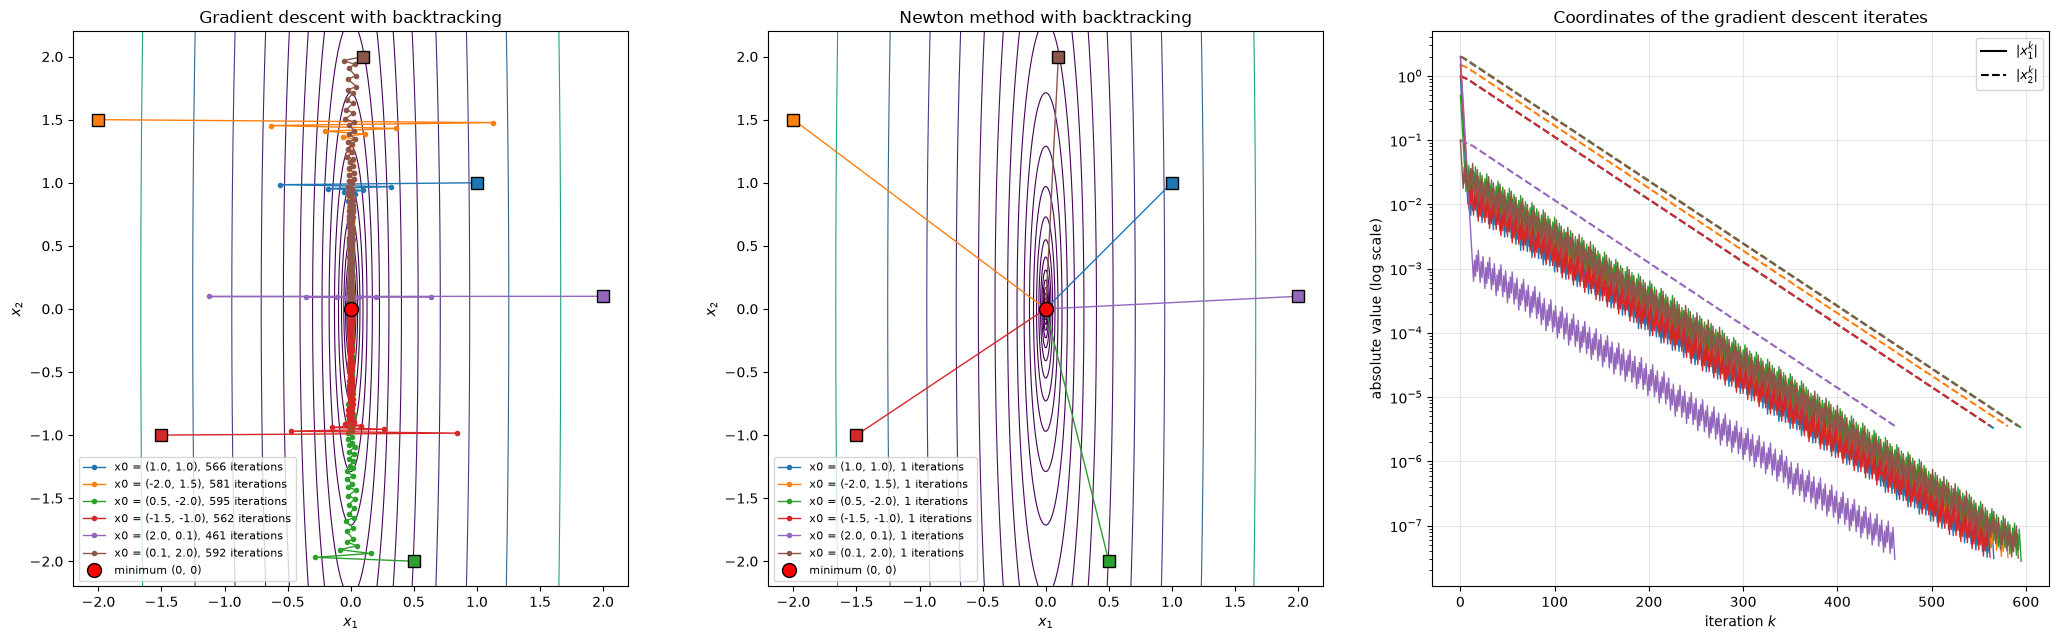

In [18]:
# PLOTS MADE WITH THE HELP OF AI

print(f"{'x0':>18} | {'gradient descent':^21} | {'Newton':^21}")
print(f"{'':>18} | {'iterations':>10} | {'halvings':>8} | {'iterations':>10} | {'halvings':>8}")
print("-" * 66)
for x0, (p_gd, a_gd, h_gd), (p_nt, a_nt, h_nt) in zip(starts_q, results_gd_q, results_nt_q):
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(p_gd) - 1:>10} | {h_gd:>8} | {len(p_nt) - 1:>10} | {h_nt:>8}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

# 1) and 2) Paths of both methods over the contour lines of f (ellipses 10 times longer in x2 than in x1)
Xq, Yq = np.meshgrid(np.linspace(-2.2, 2.2, 400), np.linspace(-2.2, 2.2, 400))
Z_q = f_q(np.array([Xq, Yq]))
for ax, results, title in zip(axes[:2], [results_gd_q, results_nt_q], ["Gradient descent", "Newton method"]):
    ax.contour(Xq, Yq, Z_q, levels=np.geomspace(0.01, Z_q.max(), 20), cmap="viridis", linewidths=0.8)
    for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_q, results)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
                label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f}), {len(path) - 1} iterations")
        ax.plot(*x0, "s", color=colors[i], mec="k", ms=9)
    ax.plot(0, 0, "o", color="red", mec="k", ms=10, label="minimum (0, 0)")
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(title + " with backtracking")
    ax.legend(fontsize=8, loc="lower left")

# 3) Absolute value of each coordinate along the gradient descent: x1 (solid) and x2 (dashed)
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_q, results_gd_q)):
    k = np.arange(len(path))
    axes[2].semilogy(k, np.abs(path[:, 0]), "-", color=colors[i], lw=1)
    axes[2].semilogy(k, np.abs(path[:, 1]), "--", color=colors[i], lw=1.5)
axes[2].plot([], [], "k-", label=r"$|x_1^{k}|$")
axes[2].plot([], [], "k--", label=r"$|x_2^{k}|$")
axes[2].set_xlabel("iteration $k$"); axes[2].set_ylabel("absolute value (log scale)")
axes[2].set_title("Coordinates of the gradient descent iterates")
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

Conclusions

- As we pointed out before, Newton needs 1 iteration from every starting point, while gradient descent needs more than 400 with thousands of halvings. Each Newton iteration is more expensive, as it needs the Hessian and solving a $2 \times 2$ linear system, but here that cost is negligible compared to hundreds of gradient iterations.
- The paths show the reason. The gradient is perpendicular to the contour lines and, since the ellipses are very elongated, it points mostly along $x_1$ and not towards the minimum. Gradient descent first zig-zags across the narrow direction $x_1$ and then crawls along the $x_2$ axis. Newton goes in a straight line from $x^{0}$ to $(0, 0)$.
- The third plot shows that, after the first iterations, both coordinates of the gradient descent iterates decrease at the same slow rate. The flat direction $x_2$ is the one that sets the speed. The lines are straight in log scale.

### 2.2 A function with multiple minima

We go back to the function of 1.2 (same $f$, gradient and Hessian). Unlike the function of 2.1, it is not convex: its Hessian is not positive definite everywhere. For example, $(0, 0)$ is a stationary point ($\nabla f(0, 0) = 0$), but there
$$
    \nabla^{2} f(0, 0) = \begin{pmatrix} 8 & 1 \\ 1 & -8 \end{pmatrix}, \qquad \lambda = \pm\sqrt{65} \approx \pm 8.06
$$

so it is a saddle point, not a minimum. Also, $f(-x) = f(x)$, so everything is symmetric with respect to the origin: starting from $-x^{0}$ gives the same path as starting from $x^{0}$, with the sign changed.

#### 2.2.1 Gradient descent from starting points far from the minima

We take six starting points inside the box $x_1 \in [-2, 2]$, $x_2 \in [-1, 1]$, all of them at a distance of at least 0.5 from every minimum, and run the gradient descent with the backtracking of 1.2.2 ($\alpha$ starts at 1 every iteration) until $\|\nabla f(x^{k})\| < 10^{-5}$, without the limit of 100 iterations. As $f(-x) = f(x)$, we only take one point of each pair $x^{0}$, $-x^{0}$. We also define the Hessian now, as we will need it in 2.2.2.

Gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5

                x0 | iterations | halvings |              final x |      f(x) | ||grad f(x)||
-----------------------------------------------------------------------------------------
  (2.0000, 1.0000) |         11 |       35 |    (0.0898, -0.7127) | -1.03e+00 |      6.87e-06
 (2.0000, -0.2000) |         10 |       35 |    (0.0898, -0.7127) | -1.03e+00 |      1.71e-06
  (1.0000, 0.9000) |         10 |       34 |    (0.0898, -0.7127) | -1.03e+00 |      5.69e-07
  (0.8000, 0.0000) |         11 |       33 |    (0.0898, -0.7127) | -1.03e+00 |      5.04e-06
 (-0.9000, 0.4000) |         11 |       37 |    (-0.0898, 0.7127) | -1.03e+00 |      4.69e-07
 (1.0000, -0.2000) |         15 |       54 |    (-1.7036, 0.7961) | -2.15e-01 |      7.79e-06


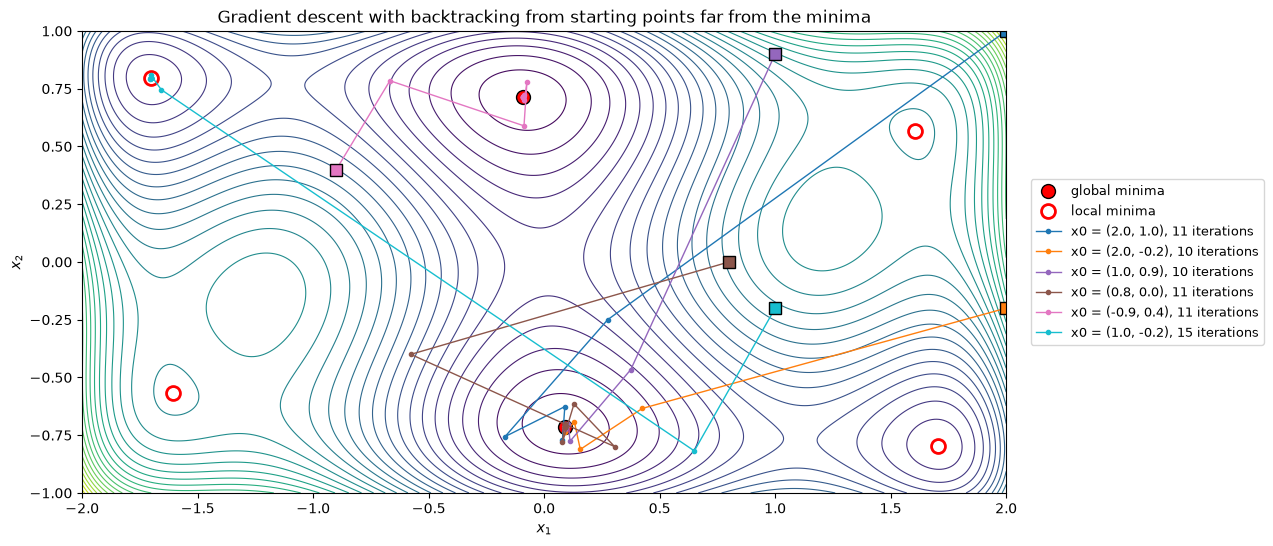

In [19]:
# MADE WITH THE HELP OF AI

def hess_f_mm(x):
    return np.array([[8 - 25.2*x[0]**2 + 10*x[0]**4, 1],
                     [1, -8 + 48*x[1]**2]])

starts_far = np.array([[2.0, 1.0], [2.0, -0.2], [1.0, 0.9], [0.8, 0.0], [-0.9, 0.4], [1.0, -0.2]])

colors_22 = [colors[j] for j in (0, 1, 4, 5, 6, 9)]

results_gd_far = [grad_desc_backtracking(f_mm, grad_f_mm, x0, tol=1e-5, max_iter=100000) for x0 in starts_far]

print("Gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5\n")
print(f"{'x0':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 89)
for x0, (path, alphas, n_halv) in zip(starts_far, results_gd_far):
    x = path[-1]
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(path) - 1:>10} | {n_halv:>8} | {f'({x[0]:.4f}, {x[1]:.4f})':>20} | "
          f"{f_mm(x):>9.2e} | {np.linalg.norm(grad_f_mm(x)):>13.2e}")

fig, ax = plt.subplots(figsize=(12, 6))
contour_mm(ax, show_minima=False)
ax.plot(minima[:2, 0], minima[:2, 1], "o", color="red", mec="k", ms=10, label="global minima")
ax.plot(minima[2:, 0], minima[2:, 1], "o", mfc="none", mec="red", mew=2, ms=10, label="local minima")
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_far, results_gd_far)):
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors_22[i], ms=3, lw=1,
            label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f}), {len(path) - 1} iterations")
    ax.plot(*x0, "s", color=colors_22[i], mec="k", ms=9)
ax.set_title(r"Gradient descent with backtracking from starting points far from the minima")
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

Conclusions

- All six runs reach a minimum in 10 to 15 iterations. Starting far away barely changes the number of iterations, because with $\alpha = 1$ the first steps are very long.
- But only $(-0.9, 0.4)$ ends at the minimum closest to it. The other five jump to another valley in the first iterations. For example, $(2.0, 1.0)$ is closest to the local minimum $(1.6071, 0.5687)$ but ends at the global minimum $(0.0898, -0.7127)$, and $(1.0, -0.2)$, closest to $(1.7036, -0.7961)$, crosses the whole box to the local minimum $(-1.7036, 0.7961)$.
- The reason is the same as in 1.2.2: far from the minima the gradient is large, so the first steps with $\alpha = 1$ are long, and backtracking only asks $f$ to decrease, not to stay in the same valley. Which minimum we reach is hard to predict from $x^{0}$.

#### 2.2.2 Newton method combined with gradient descent

The Newton direction $d_k$, solution of $\nabla^{2} f(x^{k})\, d_k = -\nabla f(x^{k})$, is only guaranteed to be a descent direction when the Hessian is positive definite, as then $\nabla f(x^{k})^{T} d_k = -\nabla f(x^{k})^{T} \left(\nabla^{2} f(x^{k})\right)^{-1} \nabla f(x^{k}) < 0$. This function is not convex, and its Hessian is not positive definite in large regions of the box: for instance, whenever $|x_2| < 1/\sqrt{6}$, its second diagonal entry $-8 + 48x_{2}^{2}$ is negative. So at every iteration:

1. We compute the Hessian $\nabla^{2} f(x^{k})$ and its eigenvalues.
2. If both eigenvalues are positive (positive definite Hessian), we use the Newton direction $d_k$. Otherwise, we use the gradient direction $d_k = -\nabla f(x^{k})$.
3. In both cases we use the backtracking of 1.2.2 ($\alpha$ starts at 1 and is halved until $f(x^{k} + \alpha^{k} d_k) < f(x^{k})$) and update $x^{k+1} = x^{k} + \alpha^{k} d_k$.

We use the same starting points and stopping criterion as in 2.2.1. In the plot, the point where each iteration starts is drawn in red if that iteration uses the gradient direction and in green if it uses the Newton direction.

Newton + gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5

                x0 | iterations | gradient | Newton | halvings |              final x |      f(x) | ||grad f(x)||
--------------------------------------------------------------------------------------------------------------------
  (2.0000, 1.0000) |          6 |        0 |      6 |        0 |     (1.6071, 0.5687) |  2.10e+00 |      3.57e-10
 (2.0000, -0.2000) |          5 |        1 |      4 |        3 |    (0.0898, -0.7127) | -1.03e+00 |      8.61e-10
  (1.0000, 0.9000) |          6 |        1 |      5 |        3 |    (0.0898, -0.7127) | -1.03e+00 |      1.41e-07
  (0.8000, 0.0000) |          5 |        2 |      3 |        3 |    (0.0898, -0.7127) | -1.03e+00 |      1.39e-06
 (-0.9000, 0.4000) |          6 |        2 |      4 |        5 |    (-0.0898, 0.7127) | -1.03e+00 |      1.09e-07
 (1.0000, -0.2000) |          5 |        2 |      3 |        2 |    (-1.7036, 0.7961) | -2.15e-01 |      2.08e-0

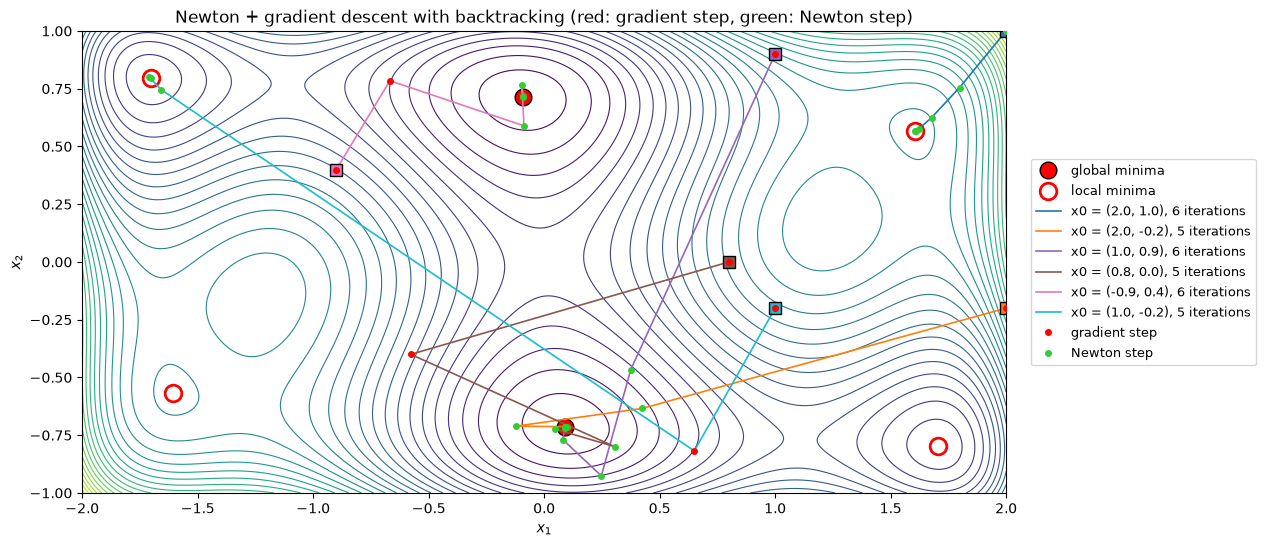

In [20]:
# MADE WITH THE HELP OF AI

def newton_gd_backtracking(f, grad_f, hess_f, x0, alpha0=1, tol=1e-5, max_iter=100, alpha_min=1e-5):
    x = x0
    path = [x]
    alphas = []
    is_newton = []
    n_halvings = 0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        hess = hess_f(x)
        if np.all(np.linalg.eigvalsh(hess) > 0):
            d = np.linalg.solve(hess, -grad)
            is_newton.append(True)
        else:
            d = -grad
            is_newton.append(False)
        alpha = alpha0
        while f(x + alpha * d) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x + alpha * d
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings, np.array(is_newton, dtype=bool)

results_hyb = [newton_gd_backtracking(f_mm, grad_f_mm, hess_f_mm, x0, tol=1e-5, max_iter=100000) for x0 in starts_far]

print("Newton + gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5\n")
print(f"{'x0':>18} | {'iterations':>10} | {'gradient':>8} | {'Newton':>6} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 116)
for x0, (path, alphas, n_halv, is_newton) in zip(starts_far, results_hyb):
    x = path[-1]
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(path) - 1:>10} | {np.sum(~is_newton):>8} | {np.sum(is_newton):>6} | {n_halv:>8} | "
          f"{f'({x[0]:.4f}, {x[1]:.4f})':>20} | {f_mm(x):>9.2e} | {np.linalg.norm(grad_f_mm(x)):>13.2e}")

fig, ax = plt.subplots(figsize=(12, 6))
contour_mm(ax, show_minima=False)
ax.plot(minima[:2, 0], minima[:2, 1], "o", color="red", mec="k", ms=12, label="global minima")
ax.plot(minima[2:, 0], minima[2:, 1], "o", mfc="none", mec="red", mew=2, ms=12, label="local minima")
for i, (x0, (path, alphas, n_halv, is_newton)) in enumerate(zip(starts_far, results_hyb)):
    ax.plot(path[:, 0], path[:, 1], "-", color=colors_22[i], lw=1.2,
            label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f}), {len(path) - 1} iterations")
    ax.plot(*x0, "s", color=colors_22[i], mec="k", ms=9)
    pts = path[:-1]  # point where the direction of each iteration is computed
    ax.plot(pts[~is_newton, 0], pts[~is_newton, 1], "o", color="red", ms=4, zorder=3)
    ax.plot(pts[is_newton, 0], pts[is_newton, 1], "o", color="limegreen", ms=4, zorder=3)
ax.plot([], [], "o", color="red", ms=4, label="gradient step")
ax.plot([], [], "o", color="limegreen", ms=4, label="Newton step")
ax.set_title("Newton + gradient descent with backtracking (red: gradient step, green: Newton step)")
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

Conclusions

- All six runs converge in 5 or 6 iterations, with only 0 to 5 halvings in total.
- Most iterations use the Newton direction.
    - From $(2.0, 1.0)$ the Hessian is already positive definite at $x^{0}$ (eigenvalues 40 and 67.2) and every iteration is a Newton step.
    - The other five starting points need 1 or 2 gradient steps first.
- As expected, near the minimum only the Newton method is used. $f$ is convex around each minimum, so once the iterate is inside a valley the Hessian is positive definite. The last iterations of every run are green.
- Newton steps almost never need halvings. Near the minimum the quadratic model is very accurate, so $\alpha = 1$ is accepted at the first try. All the halvings happen in the first two iterations, far from the minimum.
- The final points are much more precise than the tolerance requires. The last Newton step makes $\|\nabla f\|$ jump from between $10^{-5}$ and $10^{-2}$ to between $10^{-6}$ and $10^{-10}$. The number of correct digits roughly doubles at every iteration.

#### 2.2.3 Comparison of both methods

We compare the number of iterations, halvings and final points of the gradient descent (2.2.1) and the combined Newton + gradient descent (2.2.2) from the same starting points. We also plot $\|\nabla f(x^{k})\|$ along the iterations for both methods, to see how fast each of them converges.

                x0 |              gradient descent              |         Newton + gradient descent         
                   | iterations | halvings |            final x | iterations | halvings |            final x
------------------------------------------------------------------------------------------------------------
  (2.0000, 1.0000) |         11 |       35 |  (0.0898, -0.7127) |          6 |        0 |   (1.6071, 0.5687)
 (2.0000, -0.2000) |         10 |       35 |  (0.0898, -0.7127) |          5 |        3 |  (0.0898, -0.7127)
  (1.0000, 0.9000) |         10 |       34 |  (0.0898, -0.7127) |          6 |        3 |  (0.0898, -0.7127)
  (0.8000, 0.0000) |         11 |       33 |  (0.0898, -0.7127) |          5 |        3 |  (0.0898, -0.7127)
 (-0.9000, 0.4000) |         11 |       37 |  (-0.0898, 0.7127) |          6 |        5 |  (-0.0898, 0.7127)
 (1.0000, -0.2000) |         15 |       54 |  (-1.7036, 0.7961) |          5 |        2 |  (-1.7036, 0.7961)


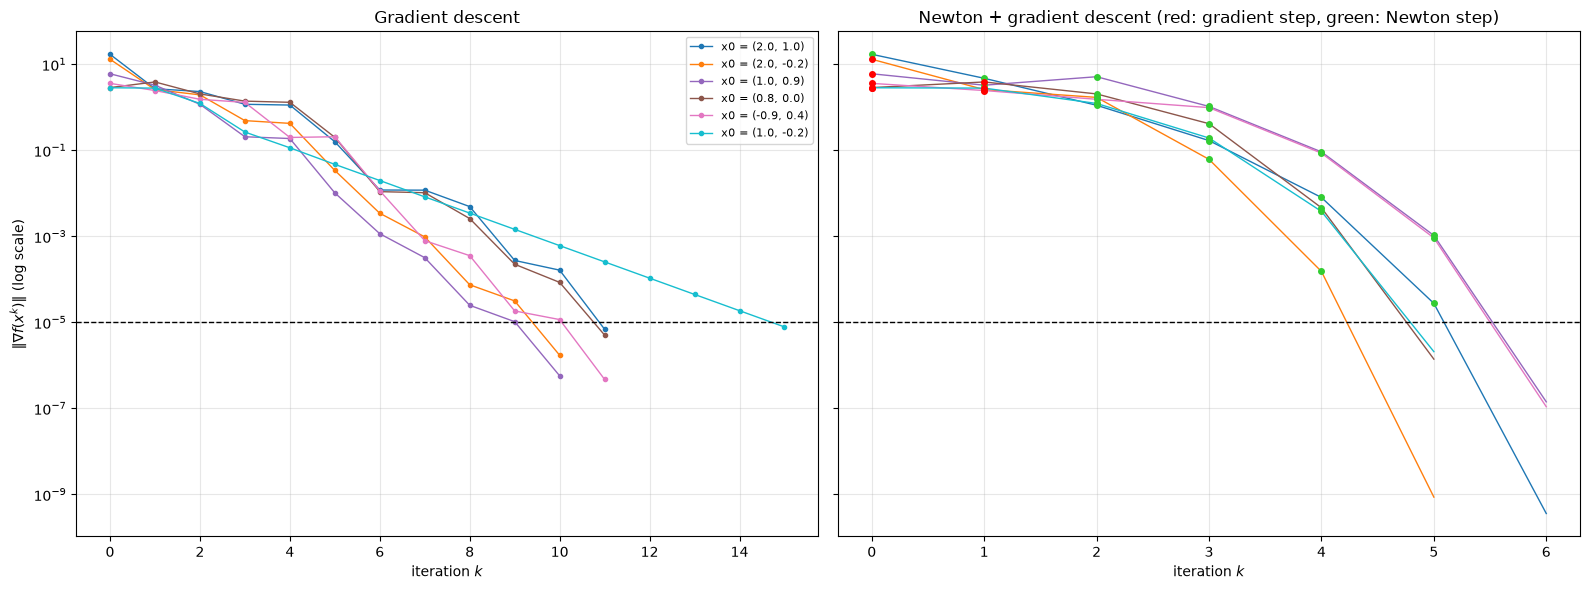

In [21]:
# PLOTS MADE WITH THE HELP OF AI

print(f"{'x0':>18} | {'gradient descent':^42} | {'Newton + gradient descent':^42}")
print(f"{'':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>18}")
print("-" * 108)
for x0, (p_gd, a_gd, h_gd), (p_hy, a_hy, h_hy, is_newton) in zip(starts_far, results_gd_far, results_hyb):
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(p_gd) - 1:>10} | {h_gd:>8} | {f'({p_gd[-1][0]:.4f}, {p_gd[-1][1]:.4f})':>18} | "
          f"{len(p_hy) - 1:>10} | {h_hy:>8} | {f'({p_hy[-1][0]:.4f}, {p_hy[-1][1]:.4f})':>18}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for i, x0 in enumerate(starts_far):
    p_gd = results_gd_far[i][0]
    axes[0].semilogy([np.linalg.norm(grad_f_mm(p)) for p in p_gd], "-o", color=colors_22[i], ms=3, lw=1,
                     label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
    p_hy, a_hy, h_hy, is_newton = results_hyb[i]
    g_hy = np.array([np.linalg.norm(grad_f_mm(p)) for p in p_hy])
    axes[1].semilogy(g_hy, "-", color=colors_22[i], lw=1)
    k = np.arange(len(p_hy) - 1)
    axes[1].plot(k[~is_newton], g_hy[:-1][~is_newton], "o", color="red", ms=4, zorder=3)
    axes[1].plot(k[is_newton], g_hy[:-1][is_newton], "o", color="limegreen", ms=4, zorder=3)
for ax, title in zip(axes, ["Gradient descent", "Newton + gradient descent (red: gradient step, green: Newton step)"]):
    ax.axhline(1e-5, color="k", ls="--", lw=1)
    ax.set_xlabel("iteration $k$"); ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$\|\nabla f(x^{k})\|$ (log scale)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Conclusions

- The combined method needs 5 or 6 iterations, against 10 to 15 for the gradient descent. The difference in halvings is even bigger, 0 to 5 against 33 to 54, so it also needs far fewer evaluations of $f$.
- The plot of $\|\nabla f(x^{k})\|$ shows the difference in the type of convergence. For the gradient descent the lines are roughly straight in log scale. $\|\nabla f\|$ is multiplied by about the same factor at every iteration. For the combined method the lines bend downwards once the Newton steps start, the last iterations go from $10^{-2}$ to below $10^{-5}$ in one or two steps.
- Both methods end at the same minimum from 5 of the 6 starting points, as the first gradient steps of the combined method also jump between valleys. The exception is $(2.0, 1.0)$, there the Hessian is positive definite from the start, so the combined method only takes Newton steps and stays in its valley, ending at the closest minimum $(1.6071, 0.5687)$, while the gradient descent jumps to the global minimum $(0.0898, -0.7127)$.
- Each Newton iteration is more expensive, as it needs the Hessian, its eigenvalues and the solution of a linear system.

### 2.3 The Rosenbrock function

We go back to the Rosenbrock function of 1.3, with $a = 1$ and $b = 100$. By differentiating the gradient, we obtain the Hessian:
$$
    \nabla^{2} f(x) = \begin{pmatrix} 2 - 4b\,(x_{2} - x_{1}^{2}) + 8b\,x_{1}^{2} & -4b\,x_{1} \\ -4b\,x_{1} & 2b \end{pmatrix}
    = \begin{pmatrix} 2 - 400x_{2} + 1200x_{1}^{2} & -400x_{1} \\ -400x_{1} & 200 \end{pmatrix}
$$

Its second diagonal entry is always positive, and its determinant is
$$
    \det \nabla^{2} f(x) = 400 - 80000\,(x_{2} - x_{1}^{2}) > 0 \quad\Longleftrightarrow\quad x_{2} < x_{1}^{2} + 0.005
$$

so the Hessian is positive definite at every point below the curve $x_2 = x_1^2 + 0.005$, which lies just above the bottom of the valley, and it is not positive definite above it.

We use the combined method of 2.2.2 (`newton_gd_backtracking`): Newton direction if the Hessian is positive definite, gradient direction otherwise, with $\alpha$ starting at 1 in every iteration, as it is the natural step for Newton. The stopping criterion is the same as in 1.3.2, $\|\nabla f(x^{k})\| < 10^{-5}$. As in 2.2.2, the points where an iteration uses the gradient direction are drawn in red and the ones where it uses the Newton direction in green.

In [22]:
# CODE OUTPUT MADE WITH THE HELP OF AI

def hess_f_rosen(x):
    return np.array([[2 - 4*b*(x[1] - x[0]**2) + 8*b*x[0]**2, -4*b*x[0]],
                     [-4*b*x[0], 2*b]])

x = np.array([-1.2, 1.0]); h = 1e-6
num = np.array([(grad_f_rosen(x + h*e) - grad_f_rosen(x - h*e)) / (2*h) for e in np.eye(2)]).T
print("analytical Hessian:\n", hess_f_rosen(x))
print("numerical Hessian:\n", num)

results_hyb_r = [newton_gd_backtracking(f_rosen, grad_f_rosen, hess_f_rosen, x0, tol=1e-5, max_iter=100000) for x0 in starts_r]

print("\nNewton + gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5\n")
print(f"{'x0':>18} | {'iterations':>10} | {'gradient':>8} | {'Newton':>6} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 116)
for x0, (path, alphas, n_halv, is_newton) in zip(starts_r, results_hyb_r):
    x = path[-1]
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(path) - 1:>10} | {np.sum(~is_newton):>8} | {np.sum(is_newton):>6} | {n_halv:>8} | "
          f"{f'({x[0]:.4f}, {x[1]:.4f})':>20} | {f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e}")

print(f"\n{'x0':>18} | {'gradient descent (1.3.2)':^72} | {'Newton + gradient descent':^25}")
print(f"{'':>18} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13} | {'iterations':>10} | {'halvings':>12}")
print("-" * 121)
for x0, (p_gd, a_gd, h_gd), (p_hy, a_hy, h_hy, is_newton) in zip(starts_r, results_r, results_hyb_r):
    x = p_gd[-1]
    print(f"{f'({x0[0]:.4f}, {x0[1]:.4f})':>18} | {len(p_gd) - 1:>10} | {h_gd:>8} | {f'({x[0]:.4f}, {x[1]:.4f})':>20} | "
          f"{f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e} | {len(p_hy) - 1:>10} | {h_hy:>12}")

analytical Hessian:
 [[1330.  480.]
 [ 480.  200.]]
numerical Hessian:
 [[1329.99999985  480.        ]
 [ 479.99999995  199.99999999]]

Newton + gradient descent with backtracking, stopping criterion: ||grad f(x)|| < 1e-5

                x0 | iterations | gradient | Newton | halvings |              final x |      f(x) | ||grad f(x)||
--------------------------------------------------------------------------------------------------------------------
 (-1.2000, 1.0000) |         21 |        0 |     21 |        7 |     (1.0000, 1.0000) |  3.74e-21 |      4.47e-10
 (-1.5000, 2.0000) |         22 |        0 |     22 |        6 |     (1.0000, 1.0000) |  1.56e-19 |      8.20e-10
  (0.0000, 0.0000) |         13 |        0 |     13 |        5 |     (1.0000, 1.0000) |  1.01e-15 |      9.80e-07
  (2.0000, 2.0000) |         14 |        0 |     14 |        5 |     (1.0000, 1.0000) |  1.10e-15 |      1.08e-06
(-1.0000, -0.5000) |         19 |        0 |     19 |        6 |     (1.0000, 1.0000) |  3

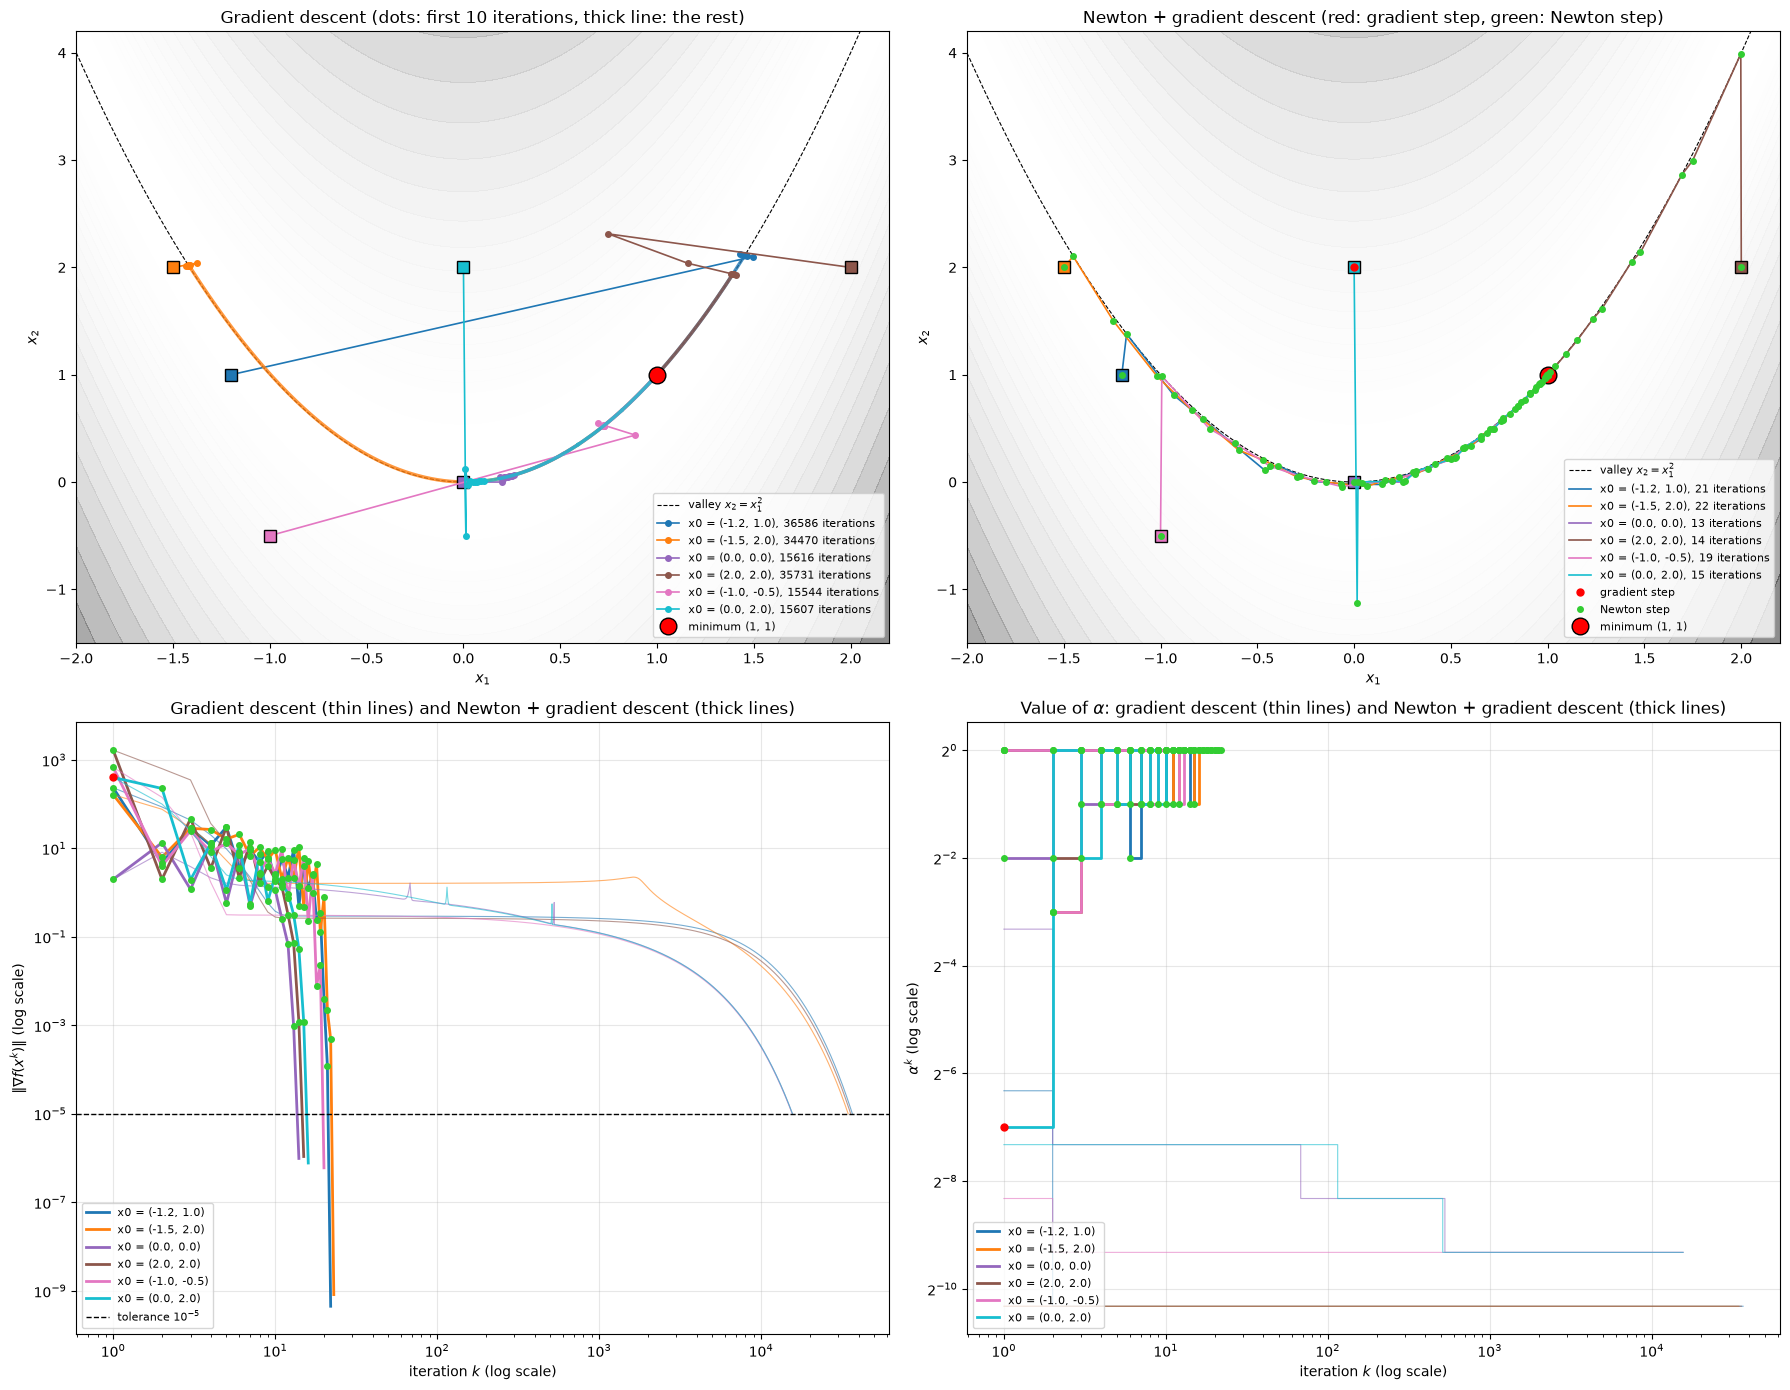

In [23]:
# PLOTS MADE WITH THE HELP OF AI

colors_23 = [colors[j] for j in (0, 1, 4, 5, 6, 9)]
fig = plt.figure(figsize=(18, 14))
ax_gd, ax_hy = fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 2)
ax_g, ax_a = fig.add_subplot(2, 2, 3), fig.add_subplot(2, 2, 4)

X1p, X2p = np.meshgrid(np.linspace(-2, 2.2, 400), np.linspace(-1.5, 4.2, 400))
Z_p = f_rosen(np.array([X1p, X2p]))
xs = np.linspace(-2, 2.2, 200)
for ax in (ax_gd, ax_hy):
    ax.contourf(X1p, X2p, Z_p, levels=np.geomspace(1, Z_p.max(), 40), cmap="Greys", alpha=0.5, extend="min")
    ax.plot(xs, xs**2, "k--", lw=0.8, label="valley $x_2 = x_1^2$")

# 1)
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    ax_gd.plot(path[:11, 0], path[:11, 1], "-o", color=colors_23[i], lw=1.2, ms=4,
               label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f}), {len(path) - 1} iterations")
    ax_gd.plot(path[10:, 0], path[10:, 1], "-", color=colors_23[i], lw=2.5, alpha=0.8)
    ax_gd.plot(*x0, "s", color=colors_23[i], mec="k", ms=9)
ax_gd.set_title("Gradient descent (dots: first 10 iterations, thick line: the rest)")

# 2)
for i, (x0, (path, alphas, n_halv, is_newton)) in enumerate(zip(starts_r, results_hyb_r)):
    ax_hy.plot(path[:, 0], path[:, 1], "-", color=colors_23[i], lw=1.2,
               label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f}), {len(path) - 1} iterations")
    ax_hy.plot(*x0, "s", color=colors_23[i], mec="k", ms=9)
    pts = path[:-1]  # point where the direction of each iteration is computed
    ax_hy.plot(pts[~is_newton, 0], pts[~is_newton, 1], "o", color="red", ms=5, zorder=3)
    ax_hy.plot(pts[is_newton, 0], pts[is_newton, 1], "o", color="limegreen", ms=4, zorder=3)
ax_hy.plot([], [], "o", color="red", ms=5, label="gradient step")
ax_hy.plot([], [], "o", color="limegreen", ms=4, label="Newton step")
ax_hy.set_title("Newton + gradient descent (red: gradient step, green: Newton step)")

for ax in (ax_gd, ax_hy):
    ax.plot(1, 1, "o", color="red", mec="k", ms=12, label="minimum (1, 1)")
    ax.set_xlim(-2, 2.2); ax.set_ylim(-1.5, 4.2)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.legend(fontsize=8, loc="lower right")

# 3)
for i, (x0, (p_gd, a_gd, h_gd), (p_hy, a_hy, h_hy, is_newton)) in enumerate(zip(starts_r, results_r, results_hyb_r)):
    g_gd = np.linalg.norm(grad_f_rosen(p_gd.T), axis=0)
    ax_g.loglog(np.arange(1, len(g_gd) + 1), g_gd, color=colors_23[i], lw=0.8, alpha=0.6)
    g_hy = np.linalg.norm(grad_f_rosen(p_hy.T), axis=0)
    k = np.arange(1, len(g_hy) + 1)
    ax_g.loglog(k, g_hy, "-", color=colors_23[i], lw=2, label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
    ax_g.plot(k[:-1][~is_newton], g_hy[:-1][~is_newton], "o", color="red", ms=5, zorder=3)
    ax_g.plot(k[:-1][is_newton], g_hy[:-1][is_newton], "o", color="limegreen", ms=4, zorder=3)
ax_g.axhline(1e-5, color="k", ls="--", lw=1, label="tolerance $10^{-5}$")
ax_g.set_xlabel("iteration $k$ (log scale)"); ax_g.set_ylabel(r"$\|\nabla f(x^{k})\|$ (log scale)")
ax_g.set_title("Gradient descent (thin lines) and Newton + gradient descent (thick lines)")
ax_g.grid(alpha=0.3)
ax_g.legend(fontsize=8, loc="lower left")

# 4)
for i, (x0, (p_gd, a_gd, h_gd), (p_hy, a_hy, h_hy, is_newton)) in enumerate(zip(starts_r, results_r, results_hyb_r)):
    ax_a.step(np.arange(1, len(a_gd) + 1), a_gd, where="post", color=colors_23[i], lw=0.8, alpha=0.6)
    k = np.arange(1, len(a_hy) + 1)
    ax_a.step(k, a_hy, where="post", color=colors_23[i], lw=2, label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
    ax_a.plot(k[~is_newton], a_hy[~is_newton], "o", color="red", ms=5, zorder=3)
    ax_a.plot(k[is_newton], a_hy[is_newton], "o", color="limegreen", ms=4, zorder=3)
ax_a.set_xscale("log"); ax_a.set_yscale("log", base=2)
ax_a.set_xlabel("iteration $k$ (log scale)"); ax_a.set_ylabel(r"$\alpha^{k}$ (log scale)")
ax_a.set_title(r"Value of $\alpha$: gradient descent (thin lines) and Newton + gradient descent (thick lines)")
ax_a.grid(alpha=0.3)
ax_a.legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.show()

Conclusions

- From the six starting points the combined method reaches $(1, 1)$ in 13 to 22 iterations, against the tens of thousands of the gradient descent, between 800 and 2500 times fewer. The final points are also more precise, with $f$ between $10^{-21}$ and $3 \cdot 10^{-13}$ against $1.25 \cdot 10^{-10}$.
- Almost every iteration is a Newton step. The Hessian is positive definite below the curve $x_2 = x_1^2 + 0.005$, and only one starting point, $(0.0, 2.0)$, is above it. From there, one gradient step, after many halvings, takes it to $(0.016, -1.125)$, and from then on all the steps are Newton steps. No iterate goes back above the curve.
- The first Newton step from each starting point goes almost vertically to the bottom of the valley. After that, the iterates follow the curved valley towards $(1, 1)$ with steps of about 0.1 to 0.2, instead of the steps of $10^{-4}$ of the gradient descent.
- As hinted in 1.3.2 this is the reason why Newton works here and the gradient descent doesn't (or works slowly). It multiplies the gradient by the inverse of the Hessian, so it divides by the large curvature across the valley and by the small curvature along it. A much better "$\alpha$" adapted to the function.
- In the last plot we can see that the gradient descent needs $\alpha$ to become small whereas in the Newton method, "$\alpha$" varies between different sizes.